In [1]:
import os, re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint

FWD, BWD, INK, MUTED, MODEL = '#2a78d6', '#eb6834', '#222222', '#8a8984', '#1baf7a'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'lines.markersize': 6, 'legend.frameon': False,
                     'axes.titlesize': 11, 'axes.labelsize': 10})
pd.set_option('display.precision', 4)

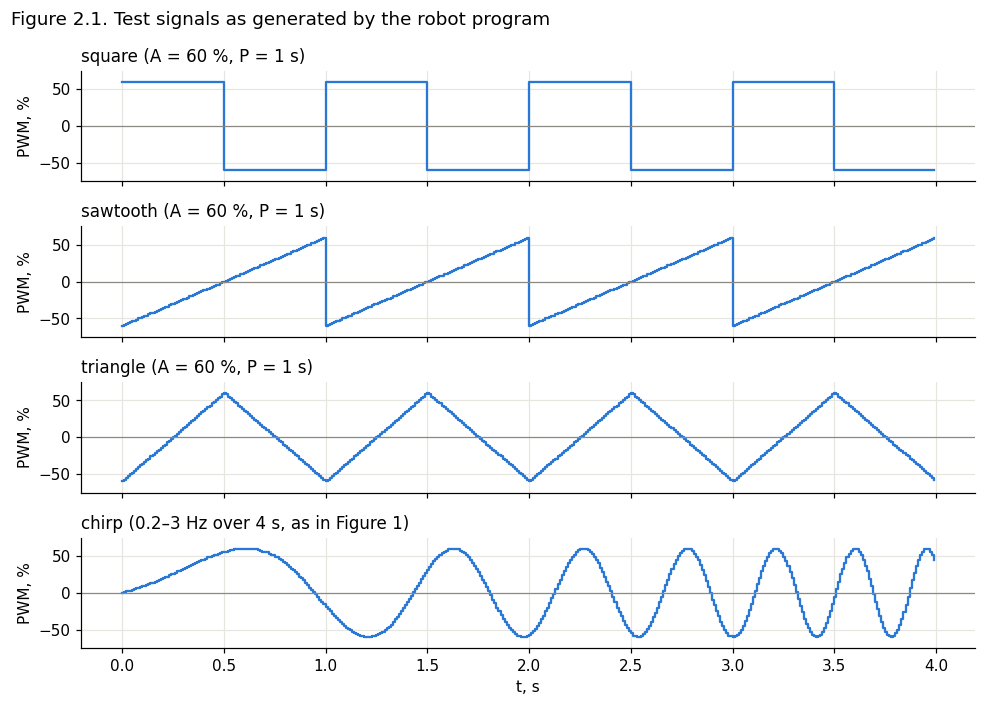

In [2]:
# Test signals exactly as computed in motor_signal.qrs (u in % PWM, t in s)
def test_signal(kind, t, A=60, P=1.0, T=8.0, f0=0.2, f1=5.0):
    ph = t / P - np.floor(t / P)
    if kind == 'square':
        uf = A * (1 - 2 * np.floor(2 * ph))
    elif kind == 'sawtooth':
        uf = A * (2 * ph - 1)
    elif kind == 'triangle':
        uf = A * (1 - 4 * np.abs(ph - 0.5))
    elif kind == 'chirp':
        uf = A * np.sin(2 * np.pi * (f0 * t + (f1 - f0) * t**2 / (2 * T)))
    return np.floor(uf + 0.5)

t_demo = np.arange(0, 4, 0.010)        # ~10 ms real sampling interval
fig, axs = plt.subplots(4, 1, figsize=(9, 6.5), sharex=True)
for ax, kind in zip(axs, ['square', 'sawtooth', 'triangle', 'chirp']):
    kw = dict(T=4.0, f0=0.2, f1=3.0) if kind == 'chirp' else {}
    ax.step(t_demo, test_signal(kind, t_demo, **kw), where='post', color=FWD)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_ylabel('PWM, %'); ax.set_ylim(-75, 75)
    ax.set_title(kind + (' (0.2–3 Hz over 4 s, as in Figure 1)' if kind == 'chirp' else ' (A = 60 %, P = 1 s)'), loc='left')
axs[-1].set_xlabel('t, s')
fig.suptitle('Figure 2.1. Test signals as generated by the robot program', x=0.01, ha='left')
fig.tight_layout()

In [3]:
# Design check for the planned signals over a range of plausible T_m
T_m_guesses = [0.05, 0.10, 0.15, 0.20]   # s; measured in section 4: median 0.11–0.15 s, chirp 0.13–0.17 s
P_sq, A_sig, f1_chirp = 1.0, 60, 5.0
omega_at_A = 10.0                        # steady-state speed at 60 % PWM, rad/s (measured in section 4: 9.9–10.9)

rows = []
for Tm in T_m_guesses:
    fc = 1 / (2 * np.pi * Tm)
    ratio_f1 = 1 / np.sqrt(1 + (2 * np.pi * f1_chirp * Tm)**2)        # speed amplitude ratio at f1
    ang_amp_deg = np.degrees(omega_at_A * ratio_f1 / (2 * np.pi * f1_chirp))
    rows.append({'T_m, s': Tm,
                 'square: half-period / T_m': (P_sq / 2) / Tm,
                 'square: % of step reached in half-period': 100 * (1 - np.exp(-(P_sq / 2) / Tm)),
                 'f_c = 1/(2πT_m), Hz': fc,
                 'chirp: f_c / 0.2 Hz': fc / 0.2,
                 'chirp: 5 Hz / f_c': f1_chirp / fc,
                 'chirp: angle amplitude at 5 Hz, deg (= counts)': ang_amp_deg})
pd.DataFrame(rows).set_index('T_m, s').round(2)

,square: half-period / T_m,square: % of step reached in half-period,"f_c = 1/(2πT_m), Hz",chirp: f_c / 0.2 Hz,chirp: 5 Hz / f_c,"chirp: angle amplitude at 5 Hz, deg (= counts)"
"T_m, s",,,,,,
0.05,10.00,100.00,3.18,15.92,1.57,9.79
0.10,5.00,99.33,1.59,7.96,3.14,5.53
0.15,3.33,96.43,1.06,5.31,4.71,3.79
0.20,2.50,91.79,0.80,3.98,6.28,2.87


In [8]:
# 4. Data processing
MOTORS = {'M4': 'left', 'M3': 'right'}
DEG_PER_COUNT = 1.0
U_BAT_DEFAULT = 12.0
LOADED_TAGS = ('floor',)
SIGNAL_PARAMS = {'square':   dict(A=60, P=1.0, T=8.0),
                 'sawtooth': dict(A=60, P=1.0, T=8.0),
                 'triangle': dict(A=60, P=1.0, T=8.0),
                 'chirp':    dict(A=60, f0=0.2, f1=5.0, T=10.0)}
DEFAULT_SIGNAL = 'square'
SMOOTH_WINDOW = 5
MIN_TURN_DEG = 10
SAT_TOL = 0.05
LINEAR_RANGE = {(m, d): (40, 100) for m in MOTORS for d in ('fwd', 'bwd')}
FIT_RMSE_MAX = 3.0

STEP_FILES = [
    'steps_M4_run1_078.txt',
    'steps_M4_run2_078.txt',
    'steps_M3_078.txt',            #
    'signal_M4_square_078.txt',
    'signal_M4_chirp_078.txt',
    'signal_M3_square_078.txt',
    'signal_M3_chirp_078.txt',
]
BATTERY = {
    'steps_M4_run1_078.txt':    [11.2],
    'steps_M4_run2_078.txt':    [11.2],
    'steps_M3_078.txt':         [11.2],
    'signal_M4_square_078.txt': [11.3],
    'signal_M4_chirp_078.txt':  [11.3],
    'signal_M3_square_078.txt': [11.3],
    'signal_M3_chirp_078.txt':  [11.3],
}

missing = [f for f in STEP_FILES if not os.path.exists(f)]
if missing:
    try:
        from google.colab import files
        print('Please upload:', ', '.join(os.path.basename(f) for f in missing))
        files.upload()
    except ImportError:
        pass
missing = [f for f in STEP_FILES if not os.path.exists(f)]
assert not missing, f'files not found: {missing}'
print('all data files found:', len(STEP_FILES))

all data files found: 7


In [20]:
def u_battery(fname):
    # mean of the voltages noted before and after the run
    v = BATTERY.get(fname)
    if not v:
        warnings.warn(f'{fname} not in battery.txt, using {U_BAT_DEFAULT} V')
        return U_BAT_DEFAULT
    return float(np.mean(v))

def parse_name(name):
    m = re.match(r'(steps|signal)_(M\d)(?:_(.+))?\.txt$', name)
    kind, motor = m.group(1), m.group(2)
    tokens = m.group(3).split('_') if m.group(3) else []
    if kind == 'signal':
        tag = next((x for x in tokens if x in SIGNAL_PARAMS), DEFAULT_SIGNAL)
    else:
        tag = next((x for x in tokens if re.fullmatch(r'run\d+', x) or x in LOADED_TAGS), 'run1')
    return kind, motor, tag

def load_logs(path):
    # file columns: angle (deg), time (ms), PWM (%).
    # If the program was run again without the file being deleted, the file holds several runs one after
    # another; time() restarts at each run, so the file is split wherever time goes backwards.
    d = np.loadtxt(path, delimiter=',', ndmin=2)
    name = os.path.basename(path)
    kind, motor, tag = parse_name(name)
    cuts = np.r_[0, np.flatnonzero(np.diff(d[:, 1]) < 0) + 1, len(d)]
    logs = []
    for i, (a, b) in enumerate(zip(cuts[:-1], cuts[1:])):
        part = d[a:b]
        if len(cuts) > 2:
            run_name, run_tag = f'{name}#{i + 1}', (f'run{i + 1}' if tag == 'run1' else f'{tag}.{i + 1}')
            print(f'{name}: run {i + 1} of {len(cuts) - 1} = rows {a + 1}–{b} (time restarts)')
        else:
            run_name, run_tag = name, tag
        logs.append(dict(name=run_name, file=name, kind=kind, motor=motor, tag=run_tag,
                         theta=np.deg2rad(part[:, 0] * DEG_PER_COUNT), t=part[:, 1] / 1000.0, pwm=part[:, 2],
                         U_bat=u_battery(run_name) if run_name in BATTERY else u_battery(name)))
    return logs

# Load all raw logs first
all_logs = [lg for p in STEP_FILES for lg in load_logs(p)]

# Split them correctly into step_logs and signal_logs
step_logs = [lg for lg in all_logs if lg['kind'] == 'steps']
signal_logs = [lg for lg in all_logs if lg['kind'] == 'signal']

pd.DataFrame([{'file': lg['name'], 'motor': lg['motor'], 'tag': lg['tag'], 'samples': len(lg['t']),
               'duration, s': lg['t'][-1] - lg['t'][0], 'mean Δt, ms': 1000 * np.mean(np.diff(lg['t'])),
               'U_battery, V': lg['U_bat']} for lg in step_logs + signal_logs])

steps_M3_078.txt: run 1 of 2 = rows 1–3044 (time restarts)
steps_M3_078.txt: run 2 of 2 = rows 3045–6253 (time restarts)


/tmp/ipykernel_1913/1722379086.py:5: UserWarning: steps_M4_run1_078.txt not in battery.txt, using 12.0 V
  warnings.warn(f'{fname} not in battery.txt, using {U_BAT_DEFAULT} V')
/tmp/ipykernel_1913/1722379086.py:5: UserWarning: steps_M4_run2_078.txt not in battery.txt, using 12.0 V
  warnings.warn(f'{fname} not in battery.txt, using {U_BAT_DEFAULT} V')
/tmp/ipykernel_1913/1722379086.py:5: UserWarning: steps_M3_078.txt not in battery.txt, using 12.0 V
  warnings.warn(f'{fname} not in battery.txt, using {U_BAT_DEFAULT} V')
/tmp/ipykernel_1913/1722379086.py:5: UserWarning: signal_M4_square_078.txt not in battery.txt, using 12.0 V
  warnings.warn(f'{fname} not in battery.txt, using {U_BAT_DEFAULT} V')
/tmp/ipykernel_1913/1722379086.py:5: UserWarning: signal_M4_chirp_078.txt not in battery.txt, using 12.0 V
  warnings.warn(f'{fname} not in battery.txt, using {U_BAT_DEFAULT} V')
/tmp/ipykernel_1913/1722379086.py:5: UserWarning: signal_M3_square_078.txt not in battery.txt, using 12.0 V
  warni

,file,motor,tag,samples,"duration, s","mean Δt, ms","U_battery, V"
0,steps_M4_run1_078.txt,M4,run1,3036,63.155,20.8089,12.0
1,steps_M4_run2_078.txt,M4,run2,3194,63.164,19.7820,12.0
2,steps_M3_078.txt#1,M3,run1,3044,60.138,19.7627,12.0
3,steps_M3_078.txt#2,M3,run2,3209,63.178,19.6939,12.0
4,signal_M4_square_078.txt,M4,square,333,8.997,27.0994,12.0
5,signal_M4_chirp_078.txt,M4,chirp,401,10.994,27.4850,12.0
6,signal_M3_square_078.txt,M3,square,338,8.999,26.7033,12.0
7,signal_M3_chirp_078.txt,M3,chirp,397,10.985,27.7399,12.0


In [21]:
def split_steps(lg):
    pwm = lg['pwm']
    edges = np.r_[0, np.flatnonzero(np.diff(pwm) != 0) + 1, len(pwm)]
    segs = []
    for a, b in zip(edges[:-1], edges[1:]):
        if pwm[a] == 0:
            continue
        c = b
        while c < len(pwm) and pwm[c] == 0:
            c += 1
        segs.append(dict(level=int(pwm[a]), on=slice(a, b), coast=slice(b, c)))
    first = segs[0]['on'].start if segs else len(pwm)
    return segs, slice(0, first)

ENC_SIGN = {}
for lg in step_logs:
    segs, _ = split_steps(lg)
    if segs:
        top = max(segs, key=lambda s: s['level'])
        th = lg['theta'][top['on']]
        ENC_SIGN.setdefault(lg['motor'], 1 if th[-1] - th[0] >= 0 else -1)

for lg in step_logs + signal_logs:
    lg['theta'] = lg['theta'] * ENC_SIGN.get(lg['motor'], 1)

print('encoder sign per motor:', ENC_SIGN)

encoder sign per motor: {'M4': 1, 'M3': 1}


In [13]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)

def fit_step(t, th):
    if abs(th[-1]) < np.deg2rad(MIN_TURN_DEG):
        return dict(moving=False, good=False, omega=0.0, omega_err=np.nan, T_m=np.nan, T_m_err=np.nan, rmse_deg=np.nan)
    k = len(t) // 2
    w0 = (th[-1] - th[k]) / (t[-1] - t[k])                      # initial guess: slope of the 2nd half
    popt, pcov = optimize.curve_fit(model, t, th, p0=[w0, 0.1],
                                    bounds=([-np.inf, 1e-3], [np.inf, 2.0]))
    err = np.sqrt(np.diag(pcov))
    res = th - model(t, *popt)
    rmse_deg = np.degrees(np.sqrt(np.mean(res**2)))
    return dict(moving=True, good=bool(rmse_deg <= FIT_RMSE_MAX and popt[1] > 2e-3),
                omega=popt[0], omega_err=err[0], T_m=popt[1], T_m_err=err[1], rmse_deg=rmse_deg)

step_rows, step_segments = [], {}
for lg in step_logs:
    segs, zero = split_steps(lg)
    lg['zero'] = zero
    step_segments[lg['name']] = segs
    for s in segs:
        t = lg['t'][s['on']] - lg['t'][s['on']][0]
        th = lg['theta'][s['on']] - lg['theta'][s['on']][0]
        f = fit_step(t, th)
        th_c = lg['theta'][s['coast']]
        coast = (th_c[-1] - lg['theta'][s['on']][-1]) if len(th_c) else np.nan
        step_rows.append(dict(file=lg['name'], motor=lg['motor'], run=lg['tag'],
                              loaded=lg['tag'] in LOADED_TAGS, level=s['level'],
                              direction='fwd' if s['level'] > 0 else 'bwd',
                              U=s['level'] / 100 * lg['U_bat'], U_bat=lg['U_bat'],
                              coast_rad=coast, **f))
steps = pd.DataFrame(step_rows)
for (motor, run), g in steps.groupby(['motor', 'run']):
    print(f'\n=== {motor} ({MOTORS.get(motor, "")}), run {run} ===')
    display(g[['level', 'U', 'moving', 'good', 'omega', 'omega_err', 'T_m', 'T_m_err', 'rmse_deg']].set_index('level'))
bad = steps[steps.moving & ~steps.good]
print(f'\nfailed fits (RMS residual > {FIT_RMSE_MAX} deg or T_m at the bound), T_m not used:')
display(bad[['file', 'level', 'omega', 'T_m', 'rmse_deg']])


=== M3 (right), run chirp ===


,U,moving,good,omega,omega_err,T_m,T_m_err,rmse_deg
level,,,,,,,,
3,0.36,False,False,0.0,NaN,NaN,NaN,NaN
5,0.60,False,False,0.0,NaN,NaN,NaN,NaN
7,0.84,False,False,0.0,NaN,NaN,NaN,NaN
10,1.20,False,False,0.0,NaN,NaN,NaN,NaN
15,1.80,False,False,0.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
50,6.00,False,False,0.0,NaN,NaN,NaN,NaN
10,1.20,False,False,0.0,NaN,NaN,NaN,NaN
-36,-4.32,False,False,0.0,NaN,NaN,NaN,NaN



=== M3 (right), run run1 ===


,U,moving,good,omega,omega_err,T_m,T_m_err,rmse_deg
level,,,,,,,,
-100,-12.0,True,True,-14.7212,0.0043,0.0280,0.0003,1.3488
-90,-10.8,True,True,-13.6923,0.0032,0.0759,0.0003,0.8761
-80,-9.6,True,True,-12.8589,0.0041,0.1119,0.0004,1.0339
-70,-8.4,True,True,-11.8993,0.0056,0.1536,0.0005,1.3009
-60,-7.2,True,True,-11.0222,0.0055,0.1915,0.0006,1.1169
-50,-6.0,True,True,-10.2001,0.0071,0.2167,0.0008,1.3629
-40,-4.8,True,True,-9.5349,0.0056,0.2617,0.0007,0.9503
-30,-3.6,True,True,-8.0205,0.0100,0.3035,0.0015,1.4836
-20,-2.4,True,True,-6.6765,0.0076,0.3136,0.0014,1.1113



=== M3 (right), run run2 ===


,U,moving,good,omega,omega_err,T_m,T_m_err,rmse_deg
level,,,,,,,,
-100,-12.0,True,True,-14.6499,0.0033,0.0489,0.0003,0.9828
-90,-10.8,True,True,-13.5960,0.0047,0.0764,0.0004,1.2965
-80,-9.6,True,True,-12.5875,0.0051,0.0999,0.0005,1.3284
-70,-8.4,True,True,-11.6649,0.0050,0.1513,0.0005,1.1410
-60,-7.2,True,True,-10.6460,0.0044,0.1907,0.0005,0.8855
-50,-6.0,True,False,-9.8742,0.0179,0.1132,0.0021,4.5430
-40,-4.8,True,True,-9.1216,0.0091,0.2346,0.0012,1.6735
-30,-3.6,True,True,-7.7515,0.0065,0.2944,0.0010,0.9893
-20,-2.4,True,True,-6.3722,0.0065,0.3301,0.0012,0.9118


... (8 outputs left out)


=== M4 (left), run square ===


,U,moving,good,omega,omega_err,T_m,T_m_err,rmse_deg
level,,,,,,,,
60,7.2,True,True,9.3763,0.0593,0.1426,0.0021,0.4702
-60,-7.2,True,False,-34.7003,226.0397,2.0000,13.9093,13.5158
60,7.2,True,False,42.3766,146.3609,2.0000,7.4139,10.5275
-60,-7.2,True,False,-38.4130,190.8631,2.0000,10.6189,11.8466
60,7.2,True,False,46.3028,150.6548,2.0000,6.9449,8.4621
-60,-7.2,True,False,-37.5116,174.0062,2.0000,9.9152,11.3577
60,7.2,True,False,41.8323,180.7433,2.0000,9.2277,10.6623
-60,-7.2,True,False,-36.3115,201.8711,2.0000,11.8787,12.6692
60,7.2,True,False,42.5005,170.0485,2.0000,8.5508,10.7388



failed fits (RMS residual > 3.0 deg or T_m at the bound), T_m not used:


,file,level,omega,T_m,rmse_deg
10,steps_M4_run1_078.txt,10,4.2950,0.0010,8.8266
16,steps_M4_run1_078.txt,70,10.8982,0.0856,3.0400
29,steps_M4_run2_078.txt,-10,-4.0707,0.0010,7.1085
55,steps_M3_078.txt#1,60,10.9355,0.1138,4.6525
65,steps_M3_078.txt#2,-50,-9.8742,0.1132,4.5430
81,signal_M4_square_078.txt,-60,-34.7003,2.0000,13.5158
82,signal_M4_square_078.txt,60,42.3766,2.0000,10.5275
83,signal_M4_square_078.txt,-60,-38.4130,2.0000,11.8466
84,signal_M4_square_078.txt,60,46.3028,2.0000,8.4621
85,signal_M4_square_078.txt,-60,-37.5116,2.0000,11.3577


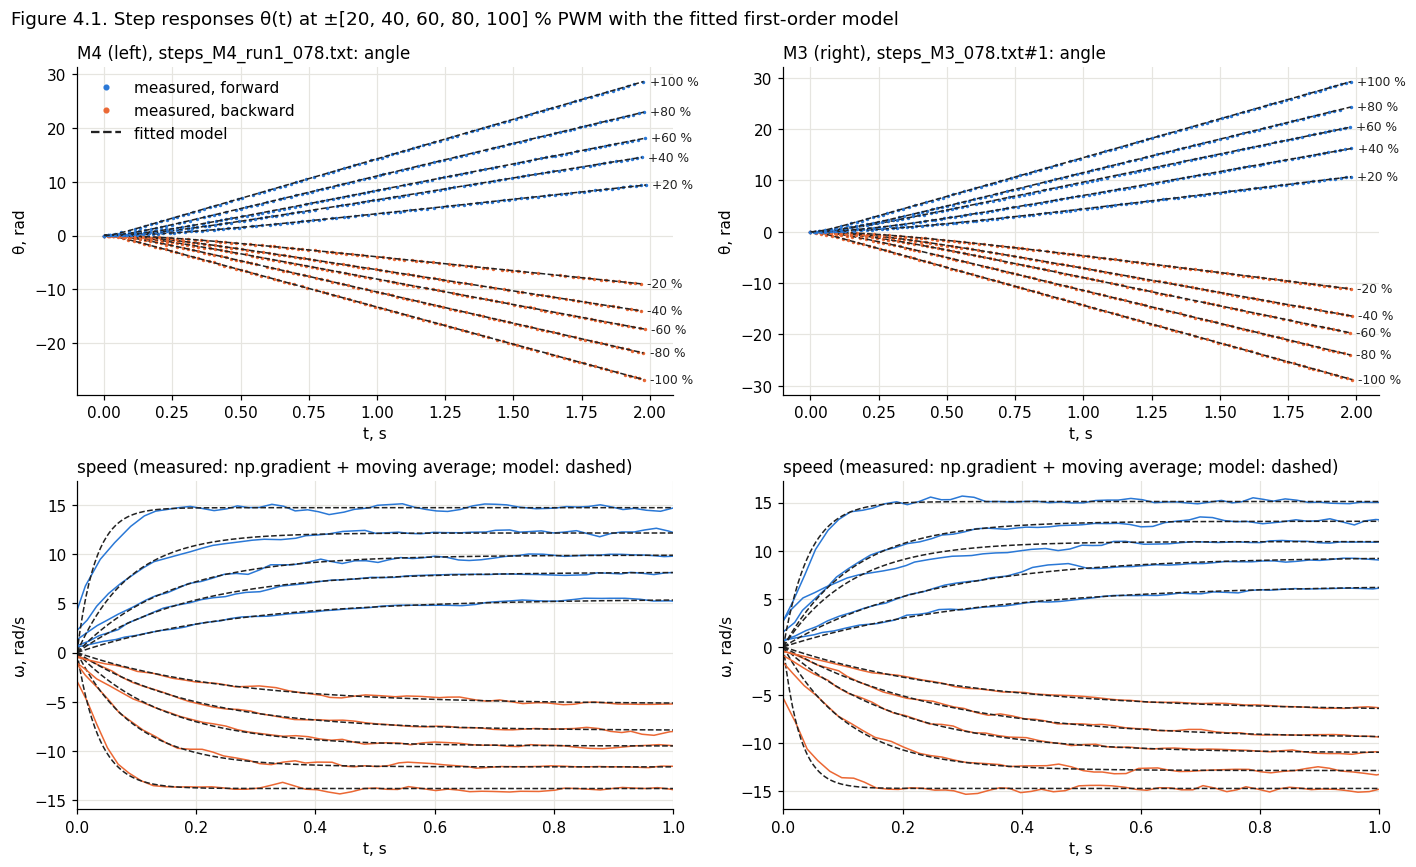

In [14]:
# Figure 4.1: step responses with the fitted model (main run of each motor)
SHOW_LEVELS = [20, 40, 60, 80, 100]
main_logs = [lg for lg in step_logs if lg['tag'] not in LOADED_TAGS]
main_logs = [next(lg for lg in main_logs if lg['motor'] == m) for m in MOTORS if any(l['motor'] == m for l in main_logs)]

fig, axs = plt.subplots(2, len(main_logs), figsize=(6.5 * len(main_logs), 8), squeeze=False)
for j, lg in enumerate(main_logs):
    ax_th, ax_w = axs[0, j], axs[1, j]
    for s in step_segments[lg['name']]:
        if abs(s['level']) not in SHOW_LEVELS:
            continue
        r = steps[(steps.file == lg['name']) & (steps.level == s['level'])].iloc[0]
        if not r.moving:
            continue
        t = lg['t'][s['on']] - lg['t'][s['on']][0]
        th = lg['theta'][s['on']] - lg['theta'][s['on']][0]
        c = FWD if s['level'] > 0 else BWD
        tt = np.linspace(0, t[-1], 400)
        ax_th.plot(t, th, '.', color=c, ms=2.5)
        ax_th.plot(tt, model(tt, r.omega, r.T_m), '--', color=INK, lw=1)
        ax_th.annotate(f"{s['level']:+d} %", (t[-1], th[-1]), xytext=(4, 0), textcoords='offset points',
                       va='center', fontsize=8, color=INK)
        w = np.convolve(np.gradient(th, t), np.ones(SMOOTH_WINDOW) / SMOOTH_WINDOW, mode='same')
        ax_w.plot(t, w, color=c, lw=1)
        ax_w.plot(tt, r.omega * (1 - np.exp(-tt / r.T_m)), '--', color=INK, lw=1)
    ax_th.set_title(f"{lg['motor']} ({MOTORS.get(lg['motor'], '')}), {lg['name']}: angle", loc='left')
    ax_th.set_xlabel('t, s'); ax_th.set_ylabel('θ, rad')
    ax_w.set_title('speed (measured: np.gradient + moving average; model: dashed)', loc='left')
    ax_w.set_xlabel('t, s'); ax_w.set_ylabel('ω, rad/s'); ax_w.set_xlim(0, 1.0)
from matplotlib.lines import Line2D
axs[0, 0].legend(handles=[Line2D([], [], color=FWD, marker='.', ls=''), Line2D([], [], color=BWD, marker='.', ls=''),
                          Line2D([], [], color=INK, ls='--')],
                 labels=['measured, forward', 'measured, backward', 'fitted model'], loc='upper left')
fig.suptitle(f'Figure 4.1. Step responses θ(t) at ±{SHOW_LEVELS} % PWM with the fitted first-order model', x=0.01, ha='left')
fig.tight_layout()

In [15]:
def linear_part(g, key):
    # g: moving and non-moving levels of one motor/direction (identification runs only)
    lv, w = g.level.abs().values.astype(float), g.omega.abs().values
    mv = g.moving.values
    if key in LINEAR_RANGE:
        lo, hi = LINEAR_RANGE[key]
    else:
        lo = lv[mv].min()
        hi = None
        for cand in sorted(set(lv[mv]), reverse=True):
            sel = mv & (lv >= lo) & (lv <= cand)
            if sel.sum() < 3:
                break
            p = np.polyfit(lv[sel], w[sel], 1)
            if np.max(np.abs(w[sel] - np.polyval(p, lv[sel]))) <= SAT_TOL * np.polyval(p, cand):
                hi = cand
                break
        hi = hi if hi is not None else lv[mv].max()
    sel = mv & (lv >= lo) & (lv <= hi)
    a, b = np.polyfit(lv[sel], w[sel], 1)
    return dict(lo=lo, hi=hi, sel=sel, slope=a, intercept=b, dz=-b / a,
                dz_lo=lv[~mv].max() if (~mv).any() else 0.0, dz_hi=lv[mv].min(),
                sat=lv[mv & (lv > hi)].min() if (mv & (lv > hi)).any() else np.nan)

ident = steps[~steps.loaded]
params, lin = {}, {}
for (motor, d), g in ident.groupby(['motor', 'direction']):
    L = linear_part(g, (motor, d))
    gl = g[L['sel']]
    Ubat = g.U_bat.mean()
    lin[(motor, d)] = L
    gl = gl[gl.good]
    params[(motor, d)] = dict(motor=motor, direction=d, dz=L['dz'], dz_cut=(L['dz_lo'] + L['dz_hi']) / 2,
                              dz_bracket=f"{L['dz_lo']:.0f}–{L['dz_hi']:.0f}",
                              slope=L['slope'], k_e=Ubat / (100 * L['slope']),
                              T_m=gl.T_m.median(), T_m_mean=gl.T_m.mean(), T_m_std=gl.T_m.std(),
                              T_m_min=gl.T_m.min(), T_m_max=gl.T_m.max(), U_bat=Ubat,
                              linear_range=f"{L['lo']:.0f}–{L['hi']:.0f}", saturation_from=L['sat'])
par = pd.DataFrame(params.values()).set_index(['motor', 'direction'])
par

dz  dz_cut dz_bracket   slope     k_e     T_m  \
motor direction                                                        
M3    bwd        250.7059    35.0      60–10 -0.1099 -1.0923  0.1513   
      fwd        328.4098    35.0      60–10 -0.0728 -1.6489  0.1474   
M4    bwd        227.1690    35.0      60–10 -0.1248 -0.9613  0.1079   
      fwd        242.9645    35.0      60–10 -0.1170 -1.0256  0.1399   

                 T_m_mean  T_m_std  T_m_min  T_m_max  U_bat linear_range  \
motor direction                                                            
M3    bwd          0.1416   0.0745   0.0280   0.2617   12.0       40–100   
      fwd          0.1355   0.0804   0.0020   0.2470   12.0       40–100   
M4    bwd          0.1166   0.0606   0.0293   0.2009   12.0       40–100   
      fwd          0.1196   0.0561   0.0309   0.1879   12.0       40–100   

                 saturation_from  
motor direction                   
M3    bwd                    NaN  
      fwd                    NaN  
M4    bwd                    NaN  
      fwd                    NaN

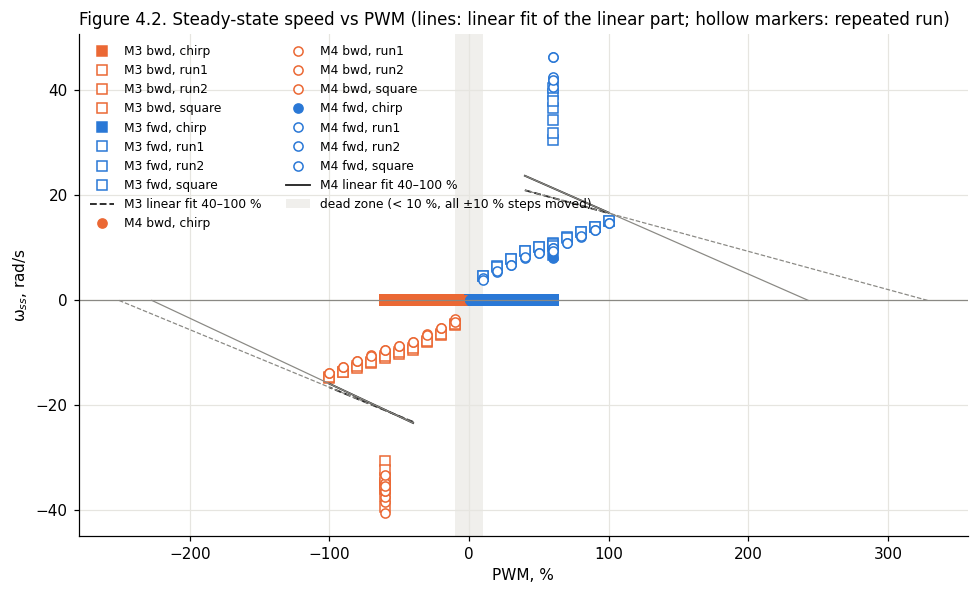

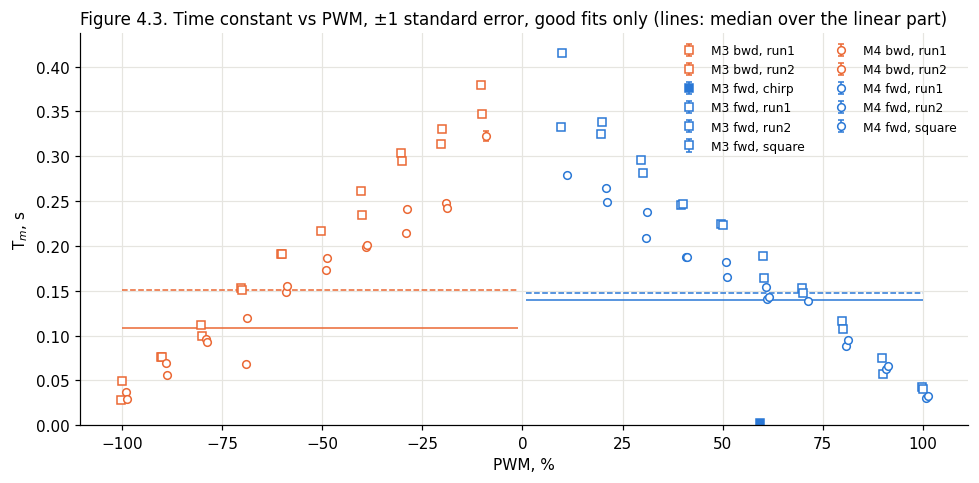

In [16]:
# Figure 4.2: steady-state speed vs PWM; Figure 4.3: T_m vs PWM
MSTYLE = {m: (mk, ls) for m, mk, ls in zip(MOTORS, ['o', 's', '^', 'D'], ['-', '--', ':', '-.'])}
runs = sorted(ident.run.unique())

fig, ax = plt.subplots(figsize=(9, 5.5))
for (motor, d), L in lin.items():
    mk, ls = MSTYLE[motor]
    c = FWD if d == 'fwd' else BWD
    sgn = 1 if d == 'fwd' else -1
    for i, run in enumerate(runs):
        g = ident[(ident.motor == motor) & (ident.direction == d) & (ident.run == run)]
        if g.empty:
            continue
        ax.plot(g.level, g.omega, mk, color=c, mfc=c if i == 0 else 'white', mec=c, ms=6, ls='',
                label=f'{motor} {d}, {run}')
    x = np.linspace(L['lo'], L['hi'], 50)                       # fitted linear part
    ax.plot(sgn * x, sgn * L['slope'] * (x - L['dz']), ls, color=INK, lw=1.2,
            label=f'{motor} linear fit {L["lo"]:.0f}–{L["hi"]:.0f} %' if d == 'fwd' else None)
    x0 = np.linspace(max(L['dz'], 0), L['lo'], 20)               # extrapolation towards 0 %
    ax.plot(sgn * x0, sgn * L['slope'] * (x0 - L['dz']), ls, color=MUTED, lw=0.8)
dzmax = max(L['dz_hi'] for L in lin.values())                  # upper end of the dead-zone bracket
ax.axvspan(-dzmax, dzmax, color='#e6e5e0', alpha=0.6, lw=0, label=f'dead zone (< {dzmax:.0f} %, all ±{dzmax:.0f} % steps moved)')
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xlabel('PWM, %'); ax.set_ylabel('ω$_{ss}$, rad/s')
ax.set_title('Figure 4.2. Steady-state speed vs PWM (lines: linear fit of the linear part; hollow markers: repeated run)', loc='left')
ax.legend(ncol=2, fontsize=8, loc='upper left')
fig.tight_layout()

fig, ax = plt.subplots(figsize=(9, 4.5))
for (motor, d), L in lin.items():
    mk, ls = MSTYLE[motor]
    c = FWD if d == 'fwd' else BWD
    for i, run in enumerate(runs):
        g = ident[(ident.motor == motor) & (ident.direction == d) & (ident.run == run) & ident.good]
        if g.empty:
            continue
        off = (0.6 if motor == list(MOTORS)[0] else -0.6) + (0.3 * i)   # small x offset so bars do not overlap
        ax.errorbar(g.level + off, g.T_m, yerr=g.T_m_err, fmt=mk, color=c, mfc=c if i == 0 else 'white',
                    ms=5, capsize=2, lw=1, label=f'{motor} {d}, {run}')
    ax.hlines(params[(motor, d)]['T_m'], *(sorted([1, 100]) if d == 'fwd' else [-100, -1]), color=c, ls=ls, lw=1)
ax.set_xlabel('PWM, %'); ax.set_ylabel('T$_m$, s'); ax.set_ylim(bottom=0)
ax.set_title('Figure 4.3. Time constant vs PWM, ±1 standard error, good fits only (lines: median over the linear part)', loc='left')
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()

In [22]:
def motor_params(motor, variant):
    f, b = params[(motor, 'fwd')], params[(motor, 'bwd')]
    if variant == 'C':
        return {+1: f, -1: b}, True, 'offset'
    avg = {k: (f[k] + b[k]) / 2 for k in ('k_e', 'T_m', 'dz', 'dz_cut')}
    return {+1: avg, -1: avg}, variant == 'B', 'cut'

# Variant D: speed and time constant tables over PWM, from the step series
mv_good = ident[ident.good]
T_COAST = (mv_good.coast_rad.abs() / mv_good.omega.abs()).groupby(mv_good.motor).median().to_dict()
TABLES = {}
for motor in MOTORS:
    g = ident[(ident.motor == motor) & ident.moving]
    if g.empty:
        continue
    w_lv = g.groupby('level').omega.median()
    T_lv = g[g.good].groupby('level').T_m.median()
    lv = np.array(sorted(set(w_lv.index) | {0}), dtype=float)
    W = np.array([0.0 if l == 0 else w_lv[l] for l in lv])
    T = np.array([T_COAST[motor] if l == 0 else T_lv.get(l, np.nan) for l in lv])
    ok = ~np.isnan(T)
    TABLES[motor] = (lv, W, np.interp(lv, lv[ok], T[ok]))
print('coasting time constant (coast angle / speed before power-off), s:', {k: round(v, 3) for k, v in T_COAST.items()})

def simulate(t, pwm, U_bat, motor, variant):
    t = t - t[0]
    hmax = np.median(np.diff(t)) / 2
    if variant in ('D', 'E'):
        lv, W, T = TABLES[motor]
        T_const = np.mean([params[(motor, d)]['T_m'] for d in ('fwd', 'bwd')])
        def ode_d(state, tt):
            speed, angle = state
            p = pwm[max(np.searchsorted(t, tt, side='right') - 1, 0)]       # zero-order hold
            T_use = np.interp(p, lv, T) if variant == 'D' else T_const
            return np.array([(np.interp(p, lv, W) - speed) / T_use, speed])
        y = odeint(ode_d, [0, 0], t, hmax=hmax)
        return y[:, 1], y[:, 0]
    U_log = pwm / 100 * U_bat
    prm, use_dz, dz_kind = motor_params(motor, variant)
    def motor_ode(state, tt):
        speed, angle = state
        u = U_log[max(np.searchsorted(t, tt, side='right') - 1, 0)]      # zero-order hold
        p = prm[1 if u >= 0 else -1]
        if use_dz:
            if dz_kind == 'cut':
                u = 0.0 if abs(u) < p['dz_cut'] / 100 * U_bat else u
            else:
                u = np.sign(u) * max(abs(u) - p['dz'] / 100 * U_bat, 0.0)
        return np.array([-speed / p['T_m'] + u / (p['T_m'] * p['k_e']), speed])
    y = odeint(motor_ode, [0, 0], t, hmax=hmax)
    return y[:, 1], y[:, 0]                                                # angle, speed

def smooth(x, n=SMOOTH_WINDOW):
    return np.convolve(x, np.ones(n) / n, mode='same')

def fit_pct(y, yh):
    return 100 * (1 - np.linalg.norm(y - yh) / np.linalg.norm(y - np.mean(y)))

def rmse(y, yh):
    return np.sqrt(np.mean((y - yh)**2))

VARIANTS = ['A', 'B', 'C', 'D', 'E']
sim_results, metric_rows = {}, []
for lg in signal_logs:
    if (lg['motor'], 'fwd') not in params:
        continue
    t = lg['t'] - lg['t'][0]
    th = lg['theta'] - lg['theta'][0]
    w = smooth(np.gradient(th, t))
    res = dict(t=t, th=th, w=w, w_raw=np.gradient(th, t), pwm=lg['pwm'], sims={})
    for v in VARIANTS:
        th_s, w_s = simulate(lg['t'], lg['pwm'], lg['U_bat'], lg['motor'], v)
        w_s = smooth(np.gradient(th_s, t))          # model speed through the same differentiation + smoothing
        res['sims'][v] = (th_s, w_s)
        metric_rows.append(dict(file=lg['name'], motor=lg['motor'], signal=lg['tag'], variant=v,
                                angle_RMSE_rad=rmse(th, th_s), angle_fit_pct=fit_pct(th, th_s),
                                speed_RMSE_rad_s=rmse(w, w_s), speed_fit_pct=fit_pct(w, w_s)))
    sim_results[lg['name']] = res
metrics = pd.DataFrame(metric_rows)
metrics.set_index(['file', 'variant']).round(3)

coasting time constant (coast angle / speed before power-off), s: {'M3': 0.3, 'M4': 0.242}


motor  signal  angle_RMSE_rad  angle_fit_pct  \
file                     variant                                                
signal_M4_square_078.txt A          M4  square           5.554       -329.112   
                         B          M4  square           5.554       -329.112   
                         C          M4  square           3.530       -172.717   
                         D          M4  square          24.443      -1788.582   
                         E          M4  square          21.519      -1562.699   
signal_M4_chirp_078.txt  A          M4   chirp           9.606       -408.976   
                         B          M4   chirp           9.181       -386.477   
                         C          M4   chirp           6.548       -246.961   
                         D          M4   chirp           9.988       -429.226   
                         E          M4   chirp           7.179       -280.405   
signal_M3_square_078.txt A          M3  square           3.089       -109.980   
                         B          M3  square           3.089       -109.980   
                         C          M3  square           2.050        -39.374   
                         D          M3  square           5.666       -285.125   
                         E          M3  square           5.200       -253.479   
signal_M3_chirp_078.txt  A          M3   chirp           6.553       -380.757   
                         B          M3   chirp           6.046       -343.512   
                         C          M3   chirp           4.272       -213.409   
                         D          M3   chirp           7.081       -419.474   
                         E          M3   chirp           3.994       -193.007   

                                  speed_RMSE_rad_s  speed_fit_pct  
file                     variant                                   
signal_M4_square_078.txt A                  10.419        -80.621  
                         B                  10.419        -80.621  
                         C                   5.769         -0.000  
                         D                  18.027       -212.499  
                         E                  19.397       -236.248  
signal_M4_chirp_078.txt  A                   5.464        -76.905  
                         B                   5.256        -70.164  
                         C                   3.178         -2.889  
                         D                   4.643        -50.310  
                         E                   5.149        -66.693  
signal_M3_square_078.txt A                   9.264        -51.676  
                         B                   9.264        -51.676  
                         C                   6.112         -0.073  
                         D                  12.581       -105.989  
                         E                  14.051       -130.046  
signal_M3_chirp_078.txt  A                   4.915        -43.934  
                         B                   4.752        -39.148  
                         C                   3.424         -0.260  
                         D                   3.495         -2.343  
                         E                   3.945        -15.525

In [19]:
print('signal_logs contains:', len(signal_logs), 'items')
print('step_logs contains:', len(step_logs), 'items')

# Let\'s see if any log is labeled as a signal in the loaded step_logs
signal_files_loaded = [lg["name"] for lg in step_logs if lg["kind"] == "signal"]
print('Signal files mistakenly loaded into step_logs instead:', signal_files_loaded)

signal_logs contains: 0 items
step_logs contains: 8 items
Signal files mistakenly loaded into step_logs instead: ['signal_M4_square_078.txt', 'signal_M4_chirp_078.txt', 'signal_M3_square_078.txt', 'signal_M3_chirp_078.txt']


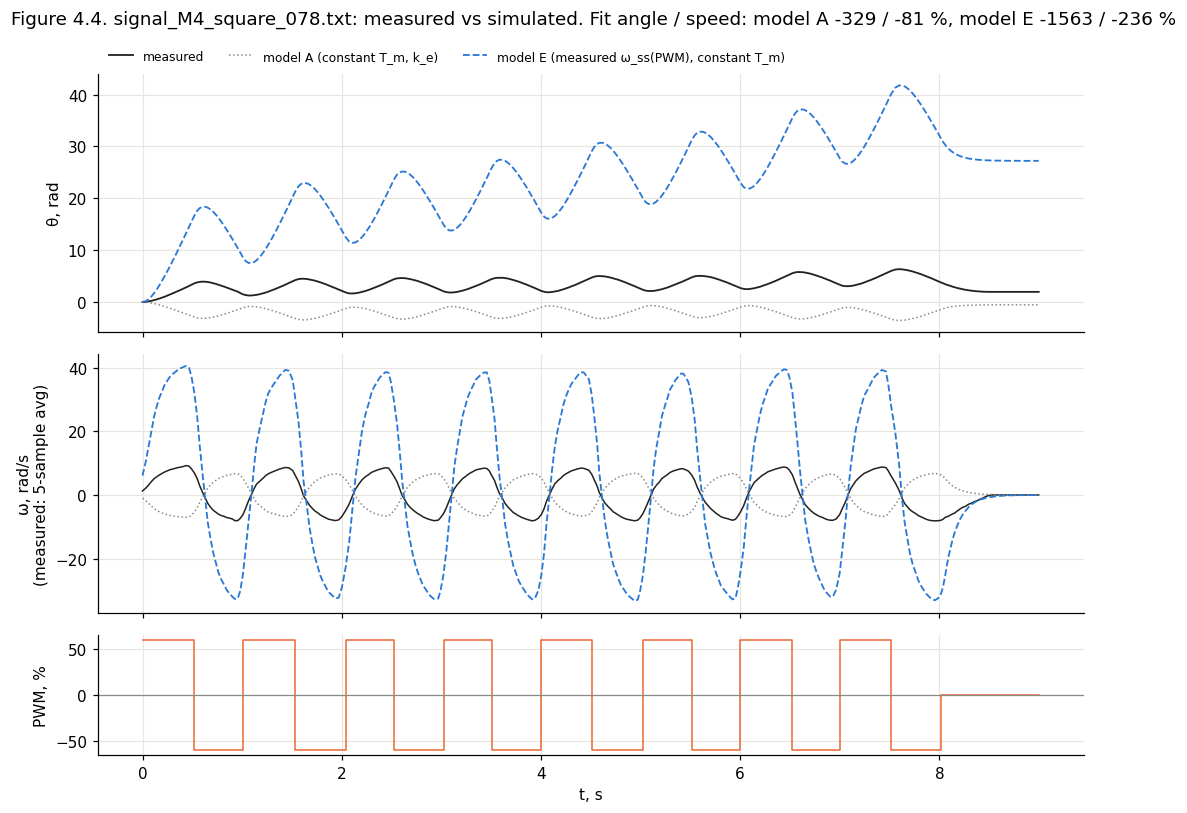

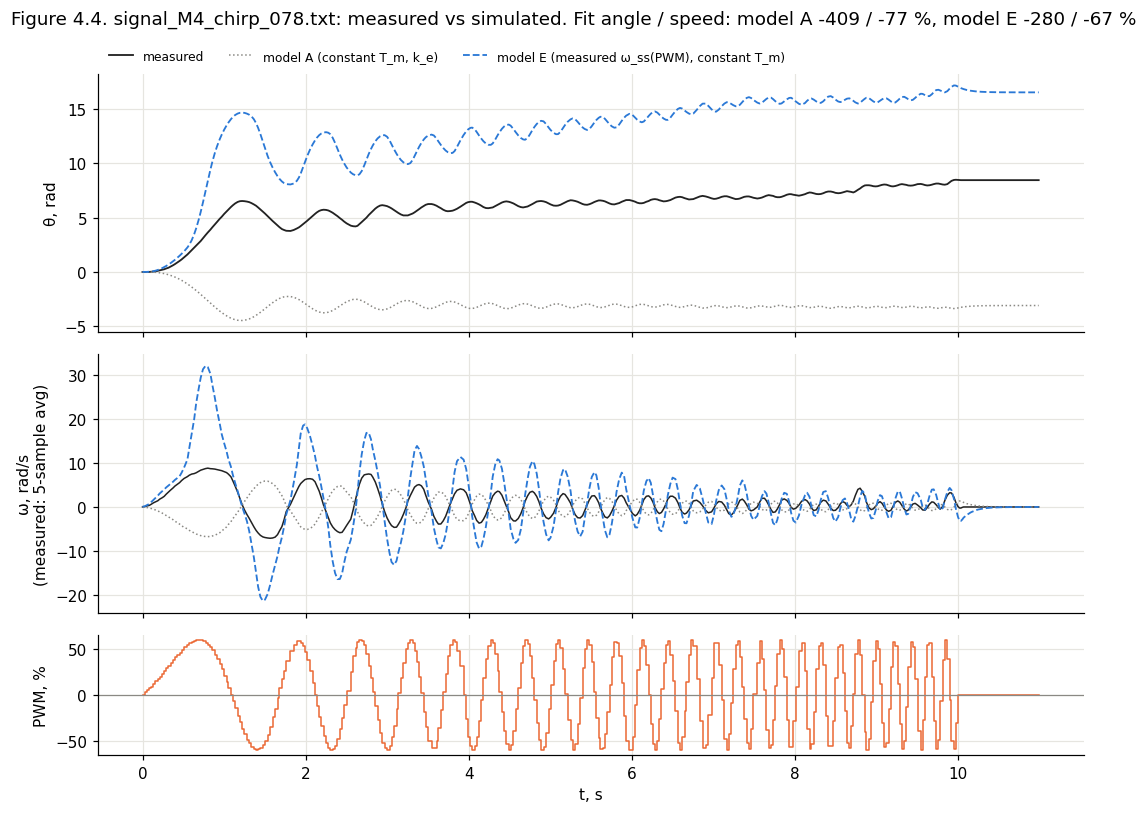

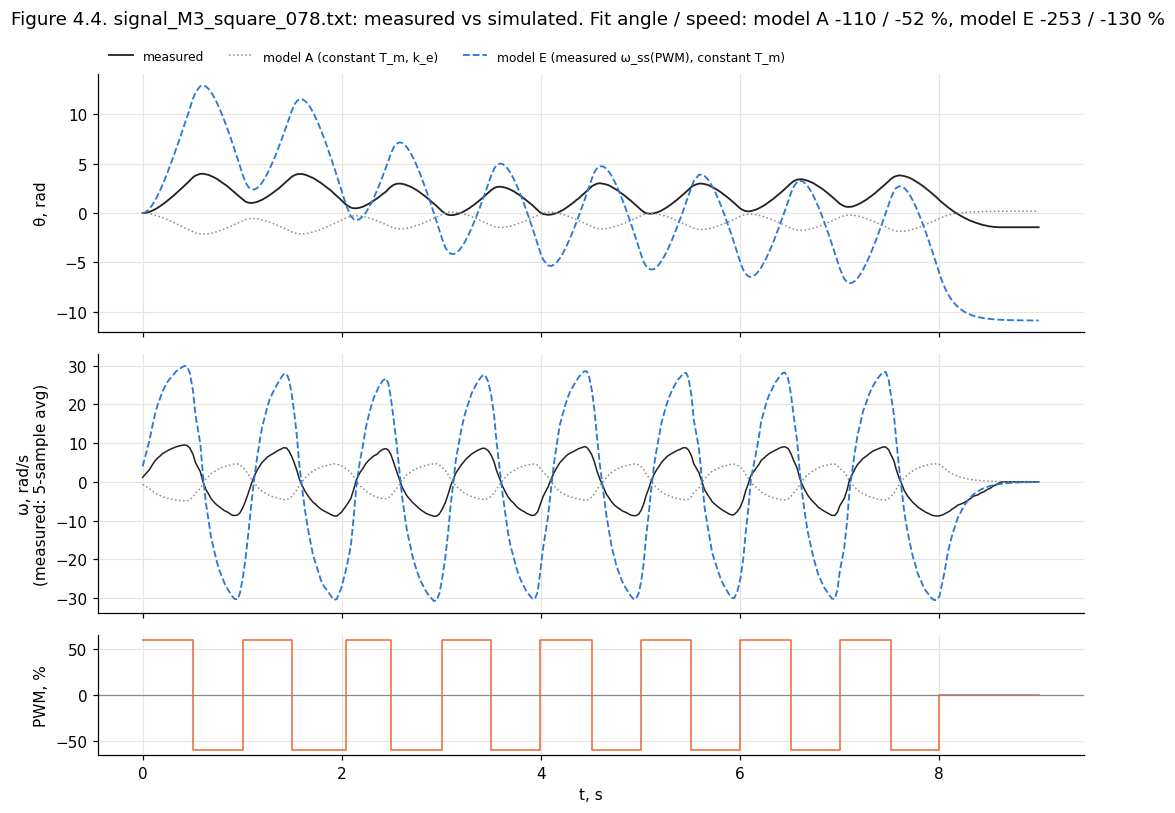

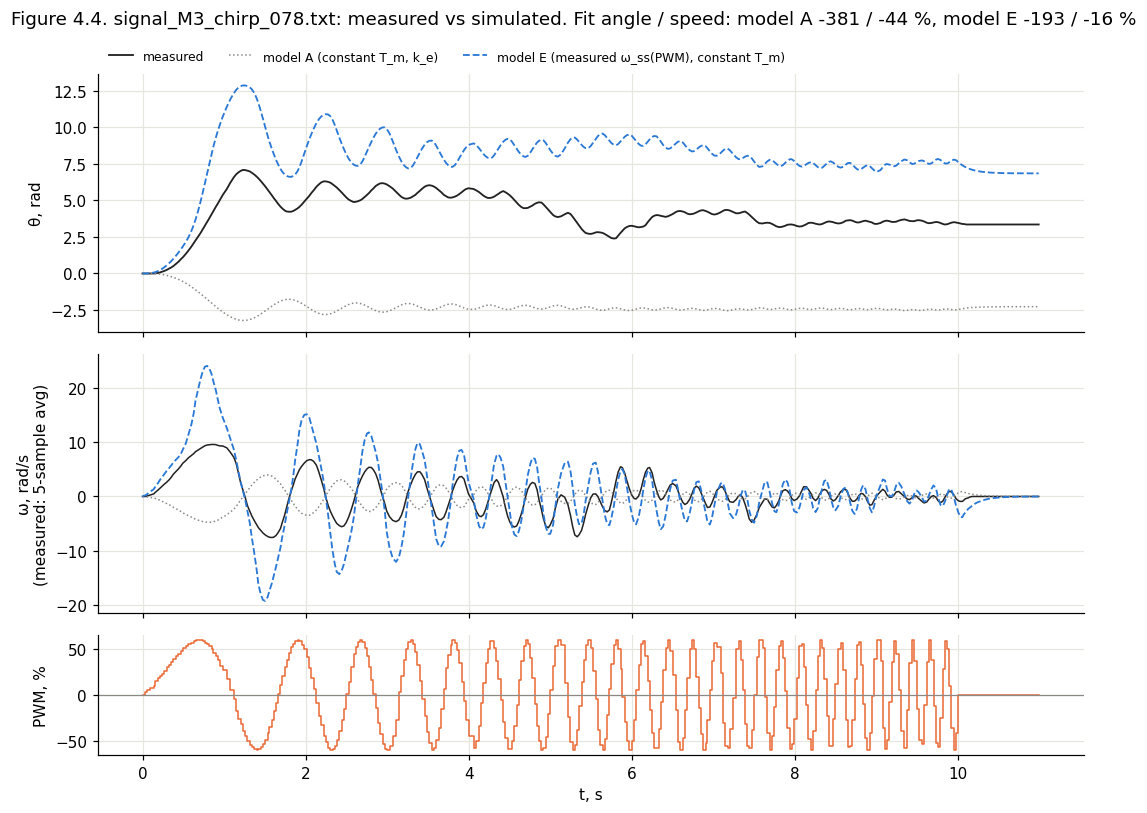

In [24]:
# Figure 4.4: measured vs simulated angle and speed, with the input PWM (one figure per signal file)
BEST = 'E'
for name, r in sim_results.items():
    fig, axs = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 3, 1.4]))
    axs[0].plot(r['t'], r['th'], color=INK, lw=1.2, label='measured')
    axs[0].plot(r['t'], r['sims']['A'][0], color=MUTED, lw=1, ls=':', label='model A (constant T_m, k_e)')
    axs[0].plot(r['t'], r['sims'][BEST][0], color=FWD, lw=1.2, ls='--', label=f'model {BEST} (measured ω_ss(PWM), constant T_m)')
    axs[0].set_ylabel('θ, rad')
    axs[0].legend(ncol=3, fontsize=8, loc='lower left', bbox_to_anchor=(0, 1.0))
    axs[1].plot(r['t'], r['w'], color=INK, lw=1)
    axs[1].plot(r['t'], r['sims']['A'][1], color=MUTED, lw=1, ls=':')
    axs[1].plot(r['t'], r['sims'][BEST][1], color=FWD, lw=1.2, ls='--')
    axs[1].set_ylabel(f'ω, rad/s\n(measured: {SMOOTH_WINDOW}-sample avg)')
    axs[2].step(r['t'], r['pwm'], where='post', color=BWD, lw=1)
    axs[2].axhline(0, color=MUTED, lw=0.8)
    axs[2].set_ylabel('PWM, %'); axs[2].set_xlabel('t, s')
    m = metrics[(metrics.file == name) & (metrics.variant == BEST)].iloc[0]
    mA = metrics[(metrics.file == name) & (metrics.variant == 'A')].iloc[0]
    fig.suptitle(f"Figure 4.4. {name}: measured vs simulated. Fit angle / speed: model A {mA.angle_fit_pct:.0f} / "
                 f"{mA.speed_fit_pct:.0f} %, model {BEST} {m.angle_fit_pct:.0f} / {m.speed_fit_pct:.0f} %", x=0.01, ha='left')
    fig.tight_layout()

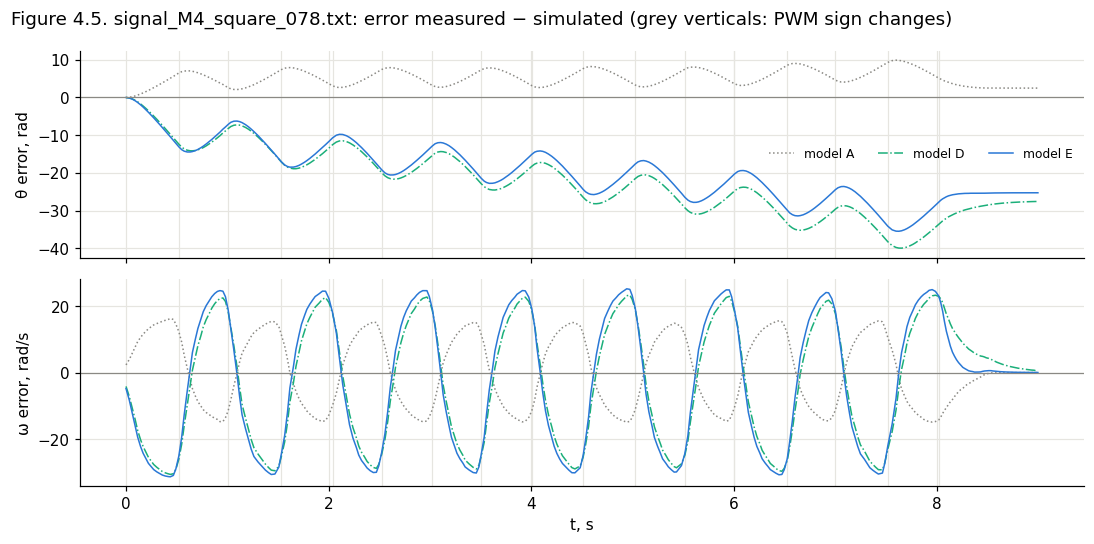

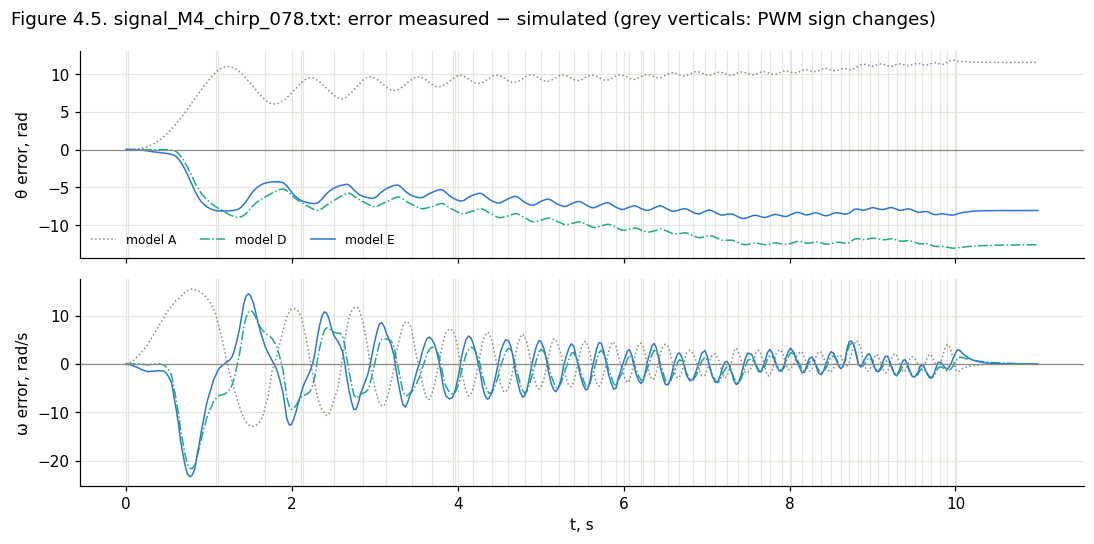

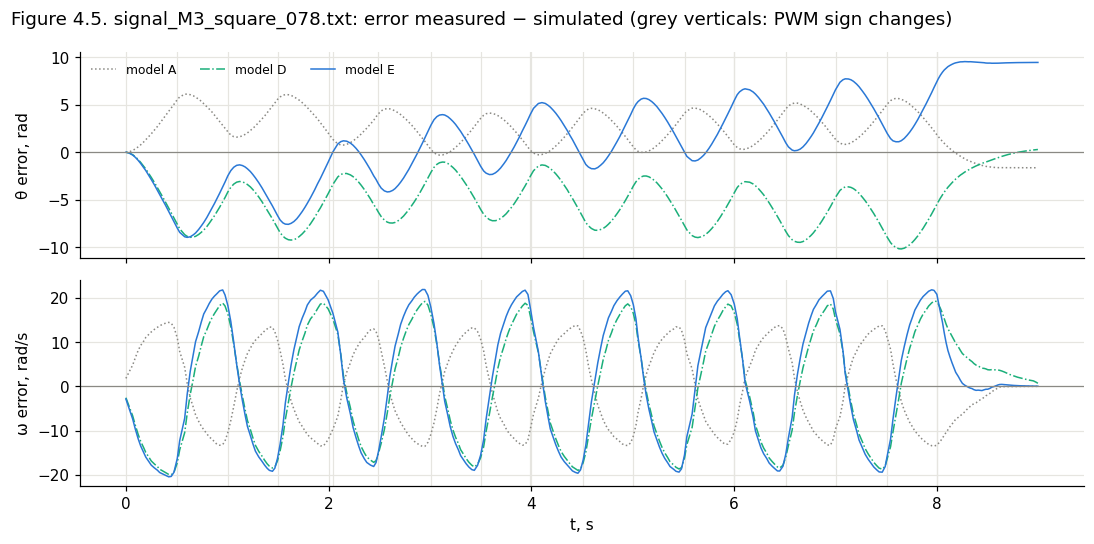

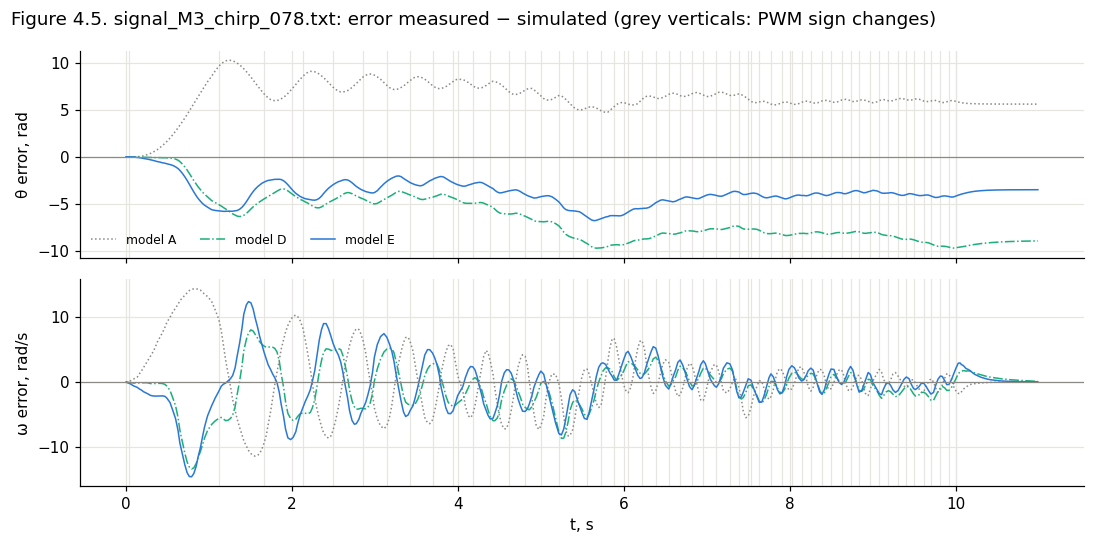

In [23]:
# Figure 4.5: error (measured - simulated) over time
for name, r in sim_results.items():
    fig, axs = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    rev = r['t'][1:][np.diff(np.sign(r['pwm'])) != 0]                 # sign changes of the command
    for v, c, ls in [('A', MUTED, ':'), ('D', MODEL, '-.'), ('E', FWD, '-')]:
        axs[0].plot(r['t'], r['th'] - r['sims'][v][0], color=c, ls=ls, lw=1, label=f'model {v}')
        axs[1].plot(r['t'], r['w'] - r['sims'][v][1], color=c, ls=ls, lw=1, label=f'model {v}')
    for ax in axs:
        for x in rev:
            ax.axvline(x, color='#e6e5e0', lw=0.8, zorder=0)
        ax.axhline(0, color=MUTED, lw=0.8)
    axs[0].set_ylabel('θ error, rad'); axs[1].set_ylabel('ω error, rad/s'); axs[1].set_xlabel('t, s')
    axs[0].legend(ncol=3, fontsize=8)
    fig.suptitle(f'Figure 4.5. {name}: error measured − simulated (grey verticals: PWM sign changes)', x=0.01, ha='left')
    fig.tight_layout()

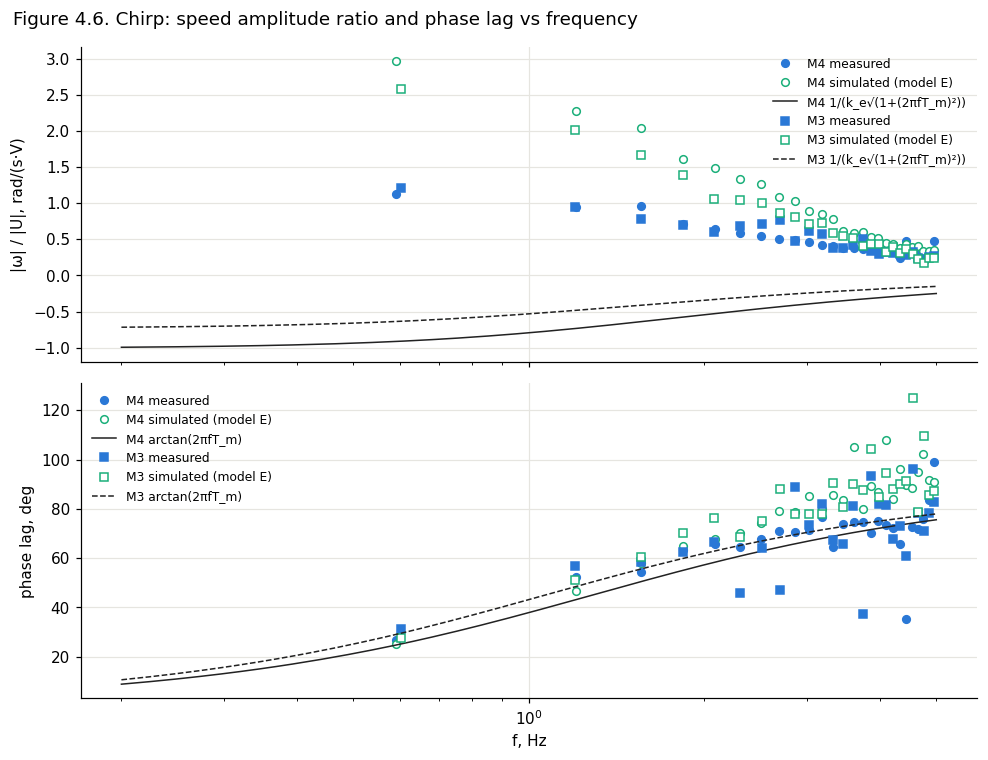

cycles  ratio measured  ratio model D  ratio model E  \
motor f band, Hz                                                         
M4    0.5–1            1           1.129          2.751          2.972   
      1–2              3           0.944          1.768          2.035   
      2–3              5           0.550          1.041          1.265   
      3–4              8           0.375          0.485          0.613   
      4–5              9           0.322          0.303          0.388   
M3    0.5–1            1           1.209          2.300          2.581   
      1–2              3           0.788          1.379          1.674   
      2–3              5           0.688          0.786          0.999   
      3–4              8           0.402          0.399          0.529   
      4–5              9           0.281          0.225          0.301   

                  lag measured, deg  lag model D, deg  lag model E, deg  \
motor f band, Hz                                                          
M4    0.5–1                  26.621            35.400            24.961   
      1–2                    54.537            74.601            57.943   
      2–3                    67.657            85.756            74.196   
      3–4                    74.203            93.399            85.412   
      4–5                    72.472           100.817            91.793   
M3    0.5–1                  31.395            39.763            27.524   
      1–2                    58.382            75.856            60.630   
      2–3                    64.102            85.664            76.127   
      3–4                    77.325            92.431            86.286   
      4–5                    78.207            96.741            90.046   

                  lag arctan(2πfT_m), deg  T_m implied by lag, s  
motor f band, Hz                                                  
M4    0.5–1                        24.733                  0.135  
      1–2                          50.510                  0.171  
      2–3                          62.818                  0.160  
      3–4                          70.042                  0.155  
      4–5                          74.230                  0.111  
M3    0.5–1                        29.560                  0.161  
      1–2                          55.566                  0.166  
      2–3                          66.968                  0.131  
      3–4                          73.204                  0.147  
      4–5                          76.822                  0.122

In [25]:
def chirp_response(t, w, A, f0, f1, T, U_bat):
    phase = 2 * np.pi * (f0 * t + (f1 - f0) * t**2 / (2 * T))
    cyc = np.floor(phase / (2 * np.pi)).astype(int)
    out = []
    for k in np.unique(cyc[t <= T]):
        sel = (cyc == k) & (t <= T)
        if sel.sum() < 6:
            continue
        X = np.c_[np.sin(phase[sel]), np.cos(phase[sel]), np.ones(sel.sum())]
        (a, b, c), *_ = np.linalg.lstsq(X, w[sel], rcond=None)
        out.append(dict(f=np.mean(f0 + (f1 - f0) * t[sel] / T), amp=np.hypot(a, b),
                        ratio=np.hypot(a, b) / (A / 100 * U_bat), lag_deg=np.degrees(np.arctan2(-b, a))))
    return pd.DataFrame(out)

chirps = [lg for lg in signal_logs if lg['tag'] == 'chirp' and lg['name'] in sim_results]
if not chirps:
    print('no chirp recording in motor_data/')
else:
    fig, axs = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    chirp_tables = []
    for lg in chirps:
        r, P = sim_results[lg['name']], SIGNAL_PARAMS['chirp']
        mk, ls = MSTYLE[lg['motor']]
        meas = chirp_response(r['t'], r['w_raw'], P['A'], P['f0'], P['f1'], P['T'], lg['U_bat'])
        simD = chirp_response(r['t'], r['sims']['D'][1], P['A'], P['f0'], P['f1'], P['T'], lg['U_bat'])
        simE = chirp_response(r['t'], r['sims']['E'][1], P['A'], P['f0'], P['f1'], P['T'], lg['U_bat'])
        k_e = np.mean([params[(lg['motor'], d)]['k_e'] for d in ('fwd', 'bwd')])
        T_m = np.mean([params[(lg['motor'], d)]['T_m'] for d in ('fwd', 'bwd')])
        ff = np.linspace(P['f0'], P['f1'], 200)
        axs[0].plot(meas.f, meas.ratio, mk, color=FWD, ms=5, label=f"{lg['motor']} measured")
        axs[0].plot(simE.f, simE.ratio, mk, color=MODEL, mfc='white', ms=5, label=f"{lg['motor']} simulated (model E)")
        axs[0].plot(ff, 1 / (k_e * np.sqrt(1 + (2 * np.pi * ff * T_m)**2)), ls, color=INK, lw=1,
                    label=f"{lg['motor']} 1/(k_e√(1+(2πfT_m)²))")
        axs[1].plot(meas.f, meas.lag_deg, mk, color=FWD, ms=5, label=f"{lg['motor']} measured")
        axs[1].plot(simE.f, simE.lag_deg, mk, color=MODEL, mfc='white', ms=5, label=f"{lg['motor']} simulated (model E)")
        axs[1].plot(ff, np.degrees(np.arctan(2 * np.pi * ff * T_m)), ls, color=INK, lw=1, label=f"{lg['motor']} arctan(2πfT_m)")
        meas['motor'] = lg['motor']
        meas['T_eff, s'] = np.tan(np.radians(meas.lag_deg)) / (2 * np.pi * meas.f)   # T_m implied by the lag
        chirp_tables.append((meas, simD, simE, T_m))
    axs[0].set_xscale('log'); axs[0].set_ylabel('|ω| / |U|, rad/(s·V)'); axs[0].legend(fontsize=8)
    axs[1].set_ylabel('phase lag, deg'); axs[1].set_xlabel('f, Hz'); axs[1].legend(fontsize=8)
    fig.suptitle('Figure 4.6. Chirp: speed amplitude ratio and phase lag vs frequency', x=0.01, ha='left')
    fig.tight_layout()
    plt.show()
    bands = [0.5, 1, 2, 3, 4, 5]
    rows = []
    for meas, simD, simE, T_m in chirp_tables:
        for lo, hi in zip(bands[:-1], bands[1:]):
            band = lambda df: df[(df.f >= lo) & (df.f < hi)]
            m, sd, se = band(meas), band(simD), band(simE)
            rows.append({'motor': meas.motor.iloc[0], 'f band, Hz': f'{lo}–{hi}', 'cycles': len(m),
                         'ratio measured': m.ratio.median(), 'ratio model D': sd.ratio.median(),
                         'ratio model E': se.ratio.median(),
                         'lag measured, deg': m.lag_deg.median(), 'lag model D, deg': sd.lag_deg.median(),
                         'lag model E, deg': se.lag_deg.median(),
                         'lag arctan(2πfT_m), deg': np.degrees(np.arctan(2 * np.pi * m.f.median() * T_m)),
                         'T_m implied by lag, s': m['T_eff, s'].median()})
    display(pd.DataFrame(rows).set_index(['motor', 'f band, Hz']).round(3))

In [29]:
#5.1 Forward vs backward asymmetry
asym = []
for motor in MOTORS:
    if (motor, 'fwd') not in params:
        continue
    f, b = params[(motor, 'fwd')], params[(motor, 'bwd')]
    pct = lambda x, y: 100 * (x - y) / ((x + y) / 2)
    w = ident[(ident.motor == motor) & ident.moving].groupby('level').omega.median()
    lo, hi = min(l for l in w.index if l > 0), max(w.index)
    asym.append({'motor': motor, 'slope fwd': f['slope'], 'slope bwd': b['slope'], 'slope diff, %': pct(f['slope'], b['slope']),
                 f'|ω| at {lo}% fwd': w[lo], f'|ω| at {lo}% bwd': -w[-lo], f'ω at {lo}% diff, %': pct(w[lo], -w[-lo]),
                 f'|ω| at {hi}% fwd': w[hi], f'|ω| at {hi}% bwd': -w[-hi], f'ω at {hi}% diff, %': pct(w[hi], -w[-hi]),
                 'T_m fwd, s': f['T_m'], 'T_m bwd, s': b['T_m'], 'T_m diff, %': pct(f['T_m'], b['T_m'])})
pd.DataFrame(asym).set_index('motor').round(3).T

motor,M4,M3
slope fwd,-0.117,-0.073
slope bwd,-0.125,-0.110
"slope diff, %",-6.469,-40.611
|ω| at 10% fwd,4.111,4.651
|ω| at 10% bwd,3.809,4.605
"ω at 10% diff, %",7.640,0.993
|ω| at 100% fwd,14.733,15.072
|ω| at 100% bwd,13.810,14.686
"ω at 100% diff, %",6.466,2.599
"T_m fwd, s",0.140,0.147


,"first time() stamp, ms","zero block length, s","encoder change, motor off, counts","max |change| in last 0.3 s of coasting, counts","net angle at end of series, deg"
file,,,,,
steps_M4_run1_078.txt,20.0,3.00,0.0,0.0,710.0
steps_M4_run2_078.txt,21.0,3.00,0.0,0.0,322.0
steps_M3_078.txt#1,3050.0,NaN,NaN,30.0,67.0
steps_M3_078.txt#2,20.0,2.98,0.0,8.0,111.0


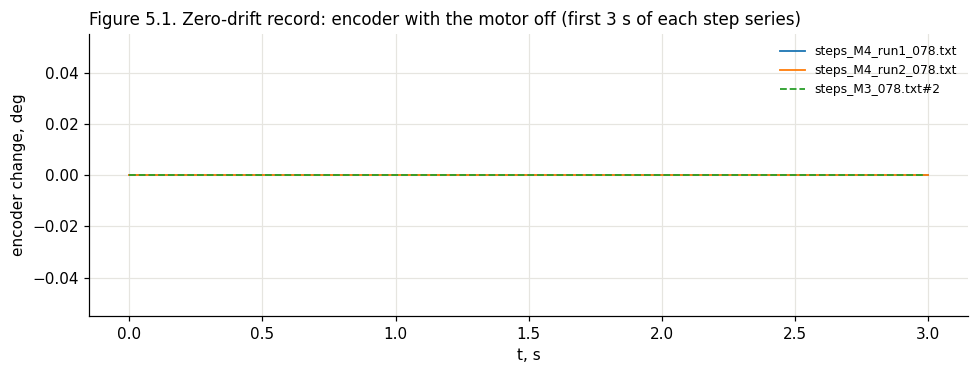

In [30]:
#5.2 Zero drift
rows = []
fig, ax = plt.subplots(figsize=(9, 3.5))
for lg in step_logs:
    z = lg.get('zero')
    if z is None:
        _, z = split_steps(lg)

    t, th = lg['t'][z], np.degrees(lg['theta'][z])
    if len(t) < 2:                                # this run has no motor-off record
        t, th = np.array([np.nan, np.nan]), np.array([np.nan, np.nan])
    else:
        mk, ls = MSTYLE[lg['motor']]
        ax.step(t - t[0], th - th[0], where='post', ls=ls, lw=1.2, label=lg['name'])
    settle = []                                   # encoder change in the last 0.3 s of each coasting part
    for s in step_segments.get(lg['name'], []):
        tc, thc = lg['t'][s['coast']], np.degrees(lg['theta'][s['coast']])
        if len(tc):
            last = tc >= tc[-1] - 0.3
            settle.append(thc[last][-1] - thc[last][0])
    rows.append({'file': lg['name'], 'first time() stamp, ms': 1000 * lg['t'][0],
                 'zero block length, s': t[-1] - t[0], 'encoder change, motor off, counts': th[-1] - th[0],
                 'max |change| in last 0.3 s of coasting, counts': np.max(np.abs(settle)) if settle else np.nan,
                 'net angle at end of series, deg': np.degrees(lg['theta'][-1] - lg['theta'][0])})
ax.set_xlabel('t, s'); ax.set_ylabel('encoder change, deg'); ax.legend(fontsize=8)
ax.set_title('Figure 5.1. Zero-drift record: encoder with the motor off (first 3 s of each step series)', loc='left')
fig.tight_layout()
pd.DataFrame(rows).set_index('file').round(2)

In [31]:
#5.3 Dead zone and 5.4 saturation
rows = []
for (motor, d), L in lin.items():
    g = ident[(ident.motor == motor) & (ident.direction == d) & ident.moving]
    w100 = g[g.level.abs() == g.level.abs().max()].omega.abs().mean()
    line100 = L['slope'] * (g.level.abs().max() - L['dz'])
    rows.append({'motor': motor, 'direction': d,
                 'dead zone (data bracket), % PWM': f"{L['dz_lo']:.0f}–{L['dz_hi']:.0f}",
                 'zero crossing of the linear-part line, % PWM': L['dz'],
                 'linear part, % PWM': f"{L['lo']:.0f}–{L['hi']:.0f}", 'saturation from, % PWM': L['sat'],
                 'ω at max PWM / line, %': 100 * w100 / line100})
display(pd.DataFrame(rows).set_index(['motor', 'direction']).round(2))

# Start-up from rest in the complex signals: the chirp starts at 0 % and rises slowly, so the PWM at which the
# encoder first moves by 2 counts is an upper bound of the dead zone (the motor's lag makes it slightly late).
rows = []
for lg in signal_logs:
    th = np.degrees(lg['theta'] - lg['theta'][0])
    k = np.flatnonzero(np.abs(th) >= 2)[0]
    rows.append({'file': lg['name'], 'first motion ≥ 2°, t, ms': 1000 * (lg['t'][k] - lg['t'][0]),
                 'PWM at that sample, %': lg['pwm'][k], 'PWM one sample earlier, %': lg['pwm'][max(k - 1, 0)]})
pd.DataFrame(rows).set_index('file')

dead zone (data bracket), % PWM  \
motor direction                                   
M3    bwd                                 60–10   
      fwd                                 60–10   
M4    bwd                                 60–10   
      fwd                                 60–10   

                 zero crossing of the linear-part line, % PWM  \
motor direction                                                 
M3    bwd                                              250.71   
      fwd                                              328.41   
M4    bwd                                              227.17   
      fwd                                              242.96   

                linear part, % PWM  saturation from, % PWM  \
motor direction                                              
M3    bwd                   40–100                     NaN   
      fwd                   40–100                     NaN   
M4    bwd                   40–100                     NaN   
      fwd                   40–100                     NaN   

                 ω at max PWM / line, %  
motor direction                          
M3    bwd                         88.70  
      fwd                         90.67  
M4    bwd                         87.00  
      fwd                         88.08

,"first motion ≥ 2°, t, ms","PWM at that sample, %","PWM one sample earlier, %"
file,,,
signal_M4_square_078.txt,62.0,60.0,60.0
signal_M4_chirp_078.txt,133.0,12.0,9.0
signal_M3_square_078.txt,67.0,60.0,60.0
signal_M3_chirp_078.txt,189.0,18.0,15.0


coast, rad  coast / (ω_ss·T_m)  T_coast = coast / ω_ss, s
motor direction                                                           
M3    bwd             3.613               1.642                      0.290
      fwd             3.159               1.546                      0.321
M4    bwd             2.164               1.752                      0.242
      fwd             2.313               1.489                      0.239

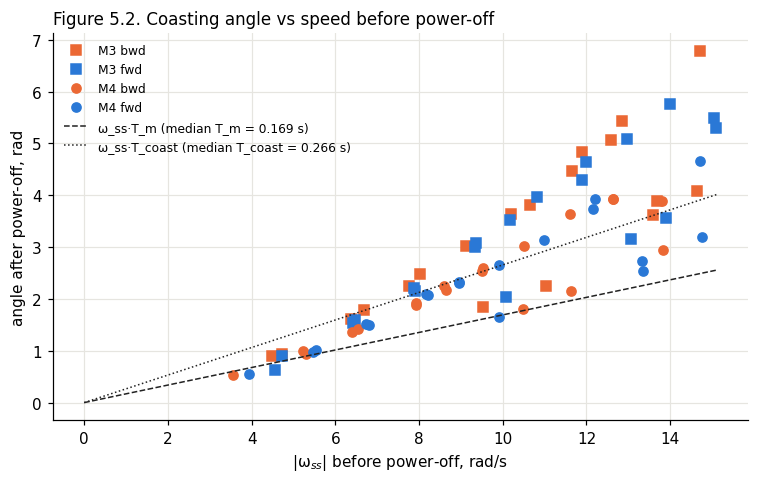

In [32]:
#5.5 Coasting after power-off
co = ident[ident.good].copy()
co['ω_ss·T_m, rad'] = co.omega.abs() * co.T_m
co['coast, rad'] = co.coast_rad.abs()
co['coast / (ω_ss·T_m)'] = co['coast, rad'] / co['ω_ss·T_m, rad']
co['T_coast = coast / ω_ss, s'] = co['coast, rad'] / co.omega.abs()
fig, ax = plt.subplots(figsize=(7, 4.5))
for (motor, d), g in co.groupby(['motor', 'direction']):
    mk, _ = MSTYLE[motor]
    ax.plot(g.omega.abs(), g['coast, rad'], mk, color=FWD if d == 'fwd' else BWD, label=f'{motor} {d}')
wmax = co.omega.abs().max()
Tm_all = co.T_m.median()
ax.plot([0, wmax], [0, wmax * Tm_all], '--', color=INK, lw=1, label=f'ω_ss·T_m (median T_m = {Tm_all:.3f} s)')
Tc_all = co['T_coast = coast / ω_ss, s'].median()
ax.plot([0, wmax], [0, wmax * Tc_all], ':', color=INK, lw=1, label=f'ω_ss·T_coast (median T_coast = {Tc_all:.3f} s)')
ax.set_xlabel('|ω$_{ss}$| before power-off, rad/s'); ax.set_ylabel('angle after power-off, rad'); ax.legend(fontsize=8)
ax.set_title('Figure 5.2. Coasting angle vs speed before power-off', loc='left')
fig.tight_layout()
co.groupby(['motor', 'direction'])[['coast, rad', 'coast / (ω_ss·T_m)', 'T_coast = coast / ω_ss, s']].median().round(3)

speed_reversal_delay_meas_ms        \
                                                    mean   std   
file                     to                                      
signal_M3_chirp_078.txt  -1                         63.0  41.8   
                          1                         70.8  40.0   
signal_M3_square_078.txt -1                        117.4   8.3   
                          1                        107.3   7.8   
signal_M4_chirp_078.txt  -1                         67.5  21.6   
                          1                         60.2  32.9   
signal_M4_square_078.txt -1                        103.0  11.7   
                          1                         86.4   6.2   

                            speed_reversal_delay_model_ms        \
                                                     mean   std   
file                     to                                       
signal_M3_chirp_078.txt  -1                          76.5  28.1   
                          1                          80.7  35.8   
signal_M3_square_078.txt -1                         117.4   8.3   
                          1                         124.9  13.9   
signal_M4_chirp_078.txt  -1                          76.6  19.1   
                          1                          71.7  28.8   
signal_M4_square_078.txt -1                         111.1   4.6   
                          1                          90.1   9.9   

                            extra_delay_ms       longest_flat_ms        
                                      mean   std            mean   std  
file                     to                                             
signal_M3_chirp_078.txt  -1          -14.3  32.5            11.0  22.6  
                          1           -9.9  32.1            12.8  13.5  
signal_M3_square_078.txt -1            0.0   0.0            10.4  14.4  
                          1          -17.6  16.6            10.3  12.9  
signal_M4_chirp_078.txt  -1          -10.3  19.2            25.8  38.0  
                          1          -11.5  19.3            16.4  22.5  
signal_M4_square_078.txt -1           -8.1  15.1            10.2  14.3  
                          1           -3.7   9.8            16.7  15.7

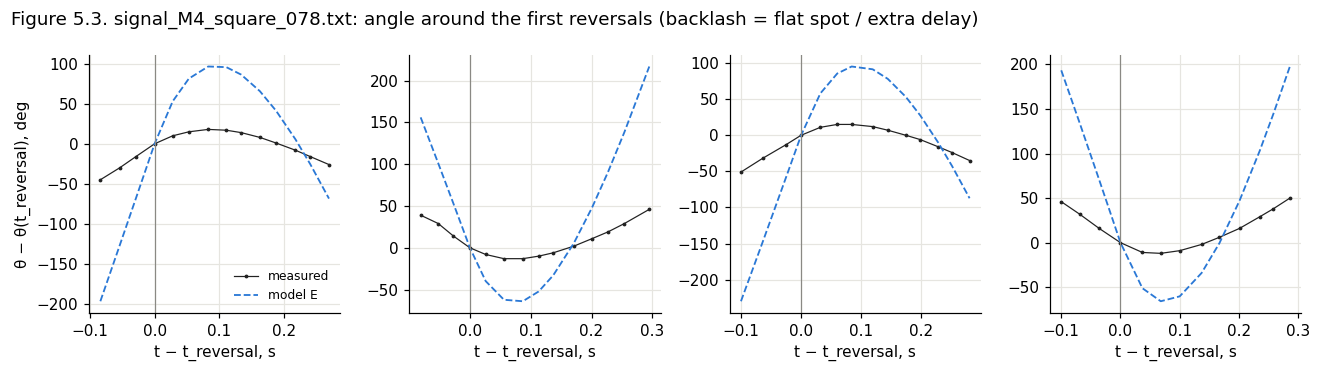

swing, deg               net shift per cycle, deg         \
                     median    min    max                   median    min   
motor f band, Hz                                                            
M3    (0, 1]          406.0  406.0  406.0                    273.0  273.0   
      (1, 2]           74.0   53.0  119.0                     19.0   19.0   
      (2, 3]           38.0   26.0   50.0                    -27.0  -41.0   
      (3, 4]           21.0   10.0   50.0                      8.0  -28.0   
      (4, 5]           10.0    5.0   15.0                      7.0   -3.0   
M4    (0, 1]          374.0  374.0  374.0                    245.0  245.0   
      (1, 2]          112.0   60.0  112.0                     33.0   30.0   
      (2, 3]           34.0   23.0   50.0                     13.0    8.0   
      (3, 4]           18.0   14.0   24.0                     10.0    3.0   
      (4, 5]           12.0    9.0   33.0                      7.0    2.0   

                         
                    max  
motor f band, Hz         
M3    (0, 1]      273.0  
      (1, 2]       37.0  
      (2, 3]        4.0  
      (3, 4]       45.0  
      (4, 5]       10.0  
M4    (0, 1]      245.0  
      (1, 2]       55.0  
      (2, 3]       21.0  
      (3, 4]       17.0  
      (4, 5]       31.0

In [33]:
#5.6 Gear backlash at direction reversals
def zero_cross_times(t, w, t_from, t_to, sign_after):
    sel = (t >= t_from) & (t < t_to)
    idx = np.flatnonzero(sel & (np.sign(w) == sign_after))
    return t[idx[0]] if len(idx) else np.nan

rows, examples = [], []
for name, r in sim_results.items():
    t, pwm = r['t'], r['pwm']
    rev = np.flatnonzero(np.sign(pwm[1:]) * np.sign(pwm[:-1]) < 0) + 1   # strict sign changes of the command
    for i, k in enumerate(rev):
        t_end = t[rev[i + 1]] if i + 1 < len(rev) else t[-1]
        s = np.sign(pwm[k])
        tm = zero_cross_times(t, r['w'], t[k], t_end, s)
        ts = zero_cross_times(t, r['sims'][BEST][1], t[k], t_end, s)
        # flat spot: longest run of unchanged encoder reading in the 0.3 s after the reversal
        win = (t >= t[k]) & (t < t[k] + 0.3)
        th = np.round(np.degrees(r['th'][win]))
        tw = t[win]
        runs_, start = [], 0
        for j in range(1, len(th) + 1):
            if j == len(th) or th[j] != th[start]:
                runs_.append(tw[j - 1] - tw[start]); start = j
        rows.append(dict(file=name, t_reversal=t[k], to=int(s),
                         speed_reversal_delay_meas_ms=1000 * (tm - t[k]),
                         speed_reversal_delay_model_ms=1000 * (ts - t[k]),
                         extra_delay_ms=1000 * (tm - ts), longest_flat_ms=1000 * max(runs_) if runs_ else np.nan))
    if len(rev):
        examples.append((name, rev))
bl = pd.DataFrame(rows)
if bl.empty:
    print('no direction reversals in the complex-signal files')
else:
    display(bl.groupby(['file', 'to'])[['speed_reversal_delay_meas_ms', 'speed_reversal_delay_model_ms',
                                        'extra_delay_ms', 'longest_flat_ms']].agg(['mean', 'std']).round(1))
    name, rev = next((e for e in examples if 'square' in e[0]), examples[0])   # square wave: cleanest reversals
    r = sim_results[name]
    picks = rev[:4]
    fig, axs = plt.subplots(1, len(picks), figsize=(3 * len(picks), 3.4), sharey=False, squeeze=False)
    for ax, k in zip(axs[0], picks):
        win = (r['t'] >= r['t'][k] - 0.1) & (r['t'] < r['t'][k] + 0.3)
        # both curves relative to their angle at the reversal, so accumulated drift does not hide the shape
        ax.plot(r['t'][win] - r['t'][k], np.degrees(r['th'][win] - r['th'][k]), '.-', color=INK, ms=3, lw=0.8, label='measured')
        ax.plot(r['t'][win] - r['t'][k], np.degrees(r['sims'][BEST][0][win] - r['sims'][BEST][0][k]), '--', color=FWD, lw=1.2,
                label=f'model {BEST}')
        ax.axvline(0, color=MUTED, lw=0.8)
        ax.set_xlabel('t − t_reversal, s')
    axs[0, 0].set_ylabel('θ − θ(t_reversal), deg'); axs[0, 0].legend(fontsize=8)
    fig.suptitle(f'Figure 5.3. {name}: angle around the first reversals (backlash = flat spot / extra delay)', x=0.01, ha='left')
    fig.tight_layout()
    plt.show()

# Chirp: per-cycle swing and net shift of the angle (a symmetric sine should give zero net shift per cycle)
rows = []
for lg in signal_logs:
    if lg['tag'] != 'chirp':
        continue
    P = SIGNAL_PARAMS['chirp']
    t, th = lg['t'] - lg['t'][0], np.degrees(lg['theta'] - lg['theta'][0])
    cyc = np.floor(P['f0'] * t + (P['f1'] - P['f0']) * t**2 / (2 * P['T'])).astype(int)
    for k in np.unique(cyc[t <= P['T']]):
        m = (cyc == k) & (t <= P['T'])
        if m.sum() >= 3:
            rows.append({'motor': lg['motor'], 'f, Hz': P['f0'] + (P['f1'] - P['f0']) * t[m].mean() / P['T'],
                         'swing, deg': np.ptp(th[m]), 'net shift per cycle, deg': th[m][-1] - th[m][0]})
if rows:
    cy = pd.DataFrame(rows)
    cy['f band, Hz'] = pd.cut(cy['f, Hz'], [0, 1, 2, 3, 4, 5])
    display(cy.groupby(['motor', 'f band, Hz'], observed=True)[['swing, deg', 'net shift per cycle, deg']]
              .agg(['median', 'min', 'max']).round(0))

,"mean Δt, ms","median, ms","min, ms","max, ms","std, ms","Δt > 2·median, %","speed quantum at median Δt, rad/s"
file,,,,,,,
steps_M4_run1_078.txt,20.81,20.0,13.0,53.0,4.24,0.66,0.87
steps_M4_run2_078.txt,19.78,20.0,13.0,44.0,2.99,0.09,0.87
steps_M3_078.txt#1,19.76,20.0,13.0,44.0,2.97,0.20,0.87
steps_M3_078.txt#2,19.69,20.0,13.0,54.0,3.03,0.12,0.87
signal_M4_square_078.txt,27.10,28.0,14.0,52.0,5.26,0.00,0.62
signal_M4_chirp_078.txt,27.48,28.0,14.0,52.0,5.22,0.00,0.62
signal_M3_square_078.txt,26.70,26.0,14.0,52.0,5.39,0.00,0.67
signal_M3_chirp_078.txt,27.74,28.0,13.0,63.0,5.53,0.25,0.62


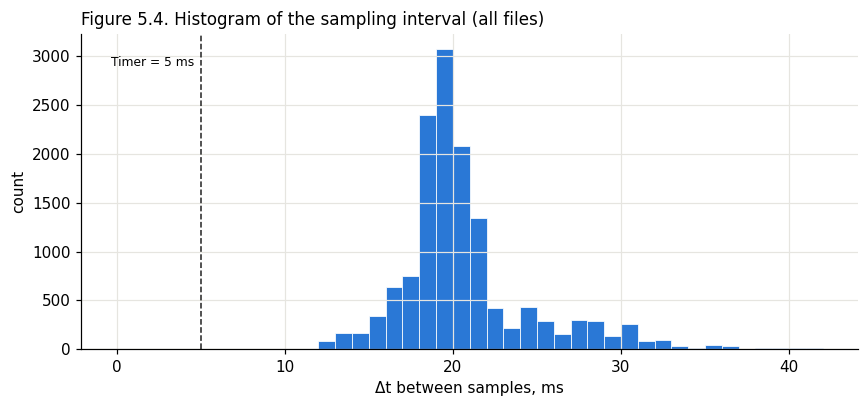

In [34]:
#5.7 Sampling jitter
rows = []
fig, ax = plt.subplots(figsize=(8, 3.8))
all_dt = []
for lg in step_logs + signal_logs:
    dt = 1000 * np.diff(lg['t'])
    all_dt.append(dt)
    rows.append({'file': lg['name'], 'mean Δt, ms': dt.mean(), 'median, ms': np.median(dt), 'min, ms': dt.min(),
                 'max, ms': dt.max(), 'std, ms': dt.std(), 'Δt > 2·median, %': 100 * np.mean(dt > 2 * np.median(dt)),
                 'speed quantum at median Δt, rad/s': np.deg2rad(DEG_PER_COUNT) / (np.median(dt) / 1000)})
all_dt = np.concatenate(all_dt)
ax.hist(all_dt, bins=np.arange(0, np.percentile(all_dt, 99.5) + 2, 1), color=FWD, edgecolor='white', linewidth=0.5)
ax.axvline(5, color=INK, ls='--', lw=1); ax.annotate('Timer = 5 ms', (5, ax.get_ylim()[1] * 0.9), xytext=(-4, 0),
                                                       textcoords='offset points', fontsize=8, ha='right')
ax.set_xlabel('Δt between samples, ms'); ax.set_ylabel('count')
ax.set_title('Figure 5.4. Histogram of the sampling interval (all files)', loc='left')
fig.tight_layout()
pd.DataFrame(rows).set_index('file').round(2)

In [36]:
#5.8 Battery sag and repeatability
BATTERY = {
    'steps_M4_run1_078.txt':    [11.2],
    'steps_M4_run2_078.txt':    [11.2],
    'steps_M3_078.txt':         [11.2],
    'signal_M4_square_078.txt': [11.3],
    'signal_M4_chirp_078.txt':  [11.3],
    'signal_M3_square_078.txt': [11.3],
    'signal_M3_chirp_078.txt':  [11.3],
}

bat_df = pd.DataFrame([{'file': k, 'U before, V': v[0], 'U after, V': v[-1] if len(v) > 1 else np.nan,
                       'ΔU, V': v[-1] - v[0] if len(v) > 1 else np.nan} for k, v in BATTERY.items()])
if not bat_df.empty:
    display(bat_df.set_index('file').round(3))
else:
    print("No battery data available")

rows = []
for motor in MOTORS:
    rr = sorted(ident[ident.motor == motor].run.unique())
    if len(rr) < 2:
        print(f'{motor}: only one step run, no repeatability comparison')
        continue
    a = ident[(ident.motor == motor) & (ident.run == rr[0]) & ident.moving].set_index('level')
    b = ident[(ident.motor == motor) & (ident.run == rr[1]) & ident.moving].set_index('level')
    common = a.index.intersection(b.index)
    ratio = b.loc[common, 'omega'] / a.loc[common, 'omega']
    ua, ub = a.U_bat.iloc[0], b.U_bat.iloc[0]
    rows.append({'motor': motor, 'runs': f'{rr[0]} → {rr[1]}', 'ω_ss ratio mean': ratio.mean(), 'ω_ss ratio std': ratio.std(),
                 'U_bat ratio': ub / ua, 'T_m diff mean, s': (b.loc[common, 'T_m'] - a.loc[common, 'T_m']).mean()})
pd.DataFrame(rows).set_index('motor').round(4) if rows else None

,"U before, V","U after, V","ΔU, V"
file,,,
steps_M4_run1_078.txt,11.2,NaN,NaN
steps_M4_run2_078.txt,11.2,NaN,NaN
steps_M3_078.txt,11.2,NaN,NaN
signal_M4_square_078.txt,11.3,NaN,NaN
signal_M4_chirp_078.txt,11.3,NaN,NaN
signal_M3_square_078.txt,11.3,NaN,NaN
signal_M3_chirp_078.txt,11.3,NaN,NaN


,runs,ω_ss ratio mean,ω_ss ratio std,U_bat ratio,"T_m diff mean, s"
motor,,,,,
M4,chirp → run1,1.2313,NaN,1.0,0.1528
M3,chirp → run1,1.2531,NaN,1.0,0.1118


,"quantum 1 count/median Δt, rad/s","std raw gradient, rad/s","std, 3-sample average","std, 5-sample average","std, 9-sample average","std, 15-sample average"
file,,,,,,
steps_M4_run1_078.txt,0.873,0.639,0.411,0.316,0.216,0.093
steps_M3_078.txt#1,0.873,0.599,0.276,0.207,0.116,0.058


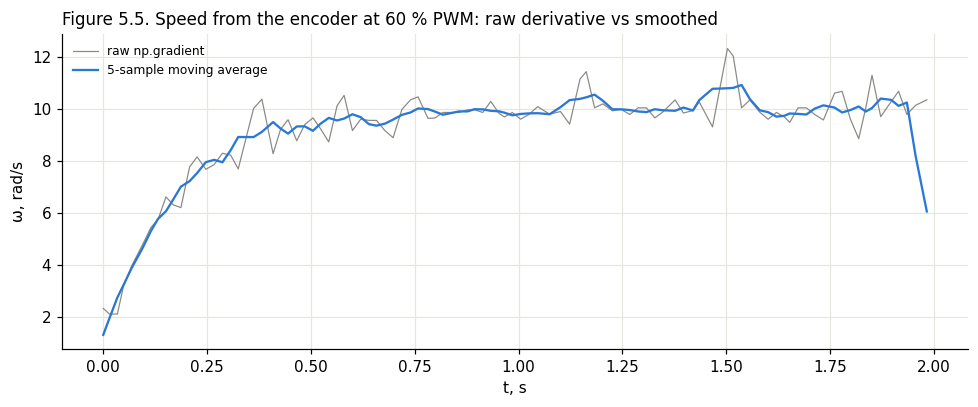

In [37]:
#5.9 Encoder quantisation and differentiation noise
REF_LEVEL = 60
rows = []
fig, ax = plt.subplots(figsize=(9, 3.8))
for lg in main_logs:
    s = next((s for s in step_segments[lg['name']] if s['level'] == REF_LEVEL), None)
    if s is None:
        continue
    t = lg['t'][s['on']] - lg['t'][s['on']][0]
    th = lg['theta'][s['on']] - lg['theta'][s['on']][0]
    w = np.gradient(th, t)
    ss = t >= t[-1] - 1.0                          # last second: steady state
    row = {'file': lg['name'], 'quantum 1 count/median Δt, rad/s': np.deg2rad(DEG_PER_COUNT) / np.median(np.diff(t)),
           'std raw gradient, rad/s': w[ss].std()}
    for n in (3, 5, 9, 15):
        row[f'std, {n}-sample average'] = smooth(w, n)[ss][n:-n].std()
    rows.append(row)
    if lg is main_logs[0]:
        ax.plot(t, w, color=MUTED, lw=0.8, label='raw np.gradient')
        ax.plot(t, smooth(w), color=FWD, lw=1.5, label=f'{SMOOTH_WINDOW}-sample moving average')
ax.set_xlabel('t, s'); ax.set_ylabel('ω, rad/s'); ax.legend(fontsize=8)
ax.set_title(f'Figure 5.5. Speed from the encoder at {REF_LEVEL} % PWM: raw derivative vs smoothed', loc='left')
fig.tight_layout()
pd.DataFrame(rows).set_index('file').round(3)

In [38]:
#5.10 Motor-to-motor spread
ms = list(MOTORS)
if len(ms) >= 2 and all((m, 'fwd') in params for m in ms[:2]):
    rows = []
    for d in ('fwd', 'bwd'):
        p1, p2 = params[(ms[0], d)], params[(ms[1], d)]
        for k, unit in [('slope', 'rad/s per %'), ('k_e', 'V·s/rad'), ('T_m', 's (median)')]:
            rows.append({'direction': d, 'parameter': f'{k}, {unit}', ms[0]: p1[k], ms[1]: p2[k],
                         'difference, %': 100 * (p1[k] - p2[k]) / ((p1[k] + p2[k]) / 2)})
    w = {m: ident[(ident.motor == m) & ident.moving].groupby('level').omega.median() for m in ms[:2]}
    for lv in (-100, -10, 10, 100):
        rows.append({'direction': 'fwd' if lv > 0 else 'bwd', 'parameter': f'ω_ss at {lv:+d} %, rad/s',
                     ms[0]: w[ms[0]][lv], ms[1]: w[ms[1]][lv],
                     'difference, %': 100 * (w[ms[0]][lv] - w[ms[1]][lv]) / ((w[ms[0]][lv] + w[ms[1]][lv]) / 2)})
    display(pd.DataFrame(rows).set_index(['direction', 'parameter']).round(4))
else:
    print('step data for both motors needed')

M4       M3  difference, %
direction parameter                                             
fwd       slope, rad/s per %     -0.1170  -0.0728        46.6085
          k_e, V·s/rad           -1.0256  -1.6489       -46.6085
          T_m, s (median)         0.1399   0.1474        -5.1915
bwd       slope, rad/s per %     -0.1248  -0.1099        12.7514
          k_e, V·s/rad           -0.9613  -1.0923       -12.7514
          T_m, s (median)         0.1079   0.1513       -33.4649
          ω_ss at -100 %, rad/s -13.8105 -14.6856        -6.1418
          ω_ss at -10 %, rad/s   -3.8085  -4.6052       -18.9370
fwd       ω_ss at +10 %, rad/s    4.1110   4.6511       -12.3276
          ω_ss at +100 %, rad/s  14.7333  15.0722        -2.2741

In [39]:
#6.1 Identified parameters
for motor in MOTORS:
    if (motor, 'fwd') not in params:
        continue
    L = {d: lin[(motor, d)] for d in ('fwd', 'bwd')}
    tbl = pd.DataFrame([{'Direction': 'Forward' if d == 'fwd' else 'Backward',
                         'Dead zone, % PWM': (f"< {L[d]['dz_hi']:.0f}" if L[d]['dz_lo'] == 0
                                              else f"{L[d]['dz_lo']:.0f}–{L[d]['dz_hi']:.0f}"),
                         'Slope, rad/s per % PWM': params[(motor, d)]['slope'],
                         'k_e, V·s/rad': params[(motor, d)]['k_e'],
                         'Mean T_m, s': params[(motor, d)]['T_m_mean'],
                         'T_m median / range, s': f"{params[(motor, d)]['T_m']:.3f} / "
                                                  f"{params[(motor, d)]['T_m_min']:.3f}–{params[(motor, d)]['T_m_max']:.3f}",
                         'U_battery, V': params[(motor, d)]['U_bat']} for d in ('fwd', 'bwd')]).set_index('Direction')
    print(f'Motor {motor} ({MOTORS[motor]} wheel)')
    display(tbl.round(4))
print('Model vs complex signal (fit %, angle / speed):')
display(metrics.pivot_table(index=['file'], columns='variant', values=['angle_fit_pct', 'speed_fit_pct']).round(1))

Motor M4 (left wheel)


,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","T_m median / range, s","U_battery, V"
Direction,,,,,,
Forward,60–10,-0.1170,-1.0256,0.1196,0.140 / 0.031–0.188,12.0
Backward,60–10,-0.1248,-0.9613,0.1166,0.108 / 0.029–0.201,12.0


Motor M3 (right wheel)


,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","T_m median / range, s","U_battery, V"
Direction,,,,,,
Forward,60–10,-0.0728,-1.6489,0.1355,0.147 / 0.002–0.247,12.0
Backward,60–10,-0.1099,-1.0923,0.1416,0.151 / 0.028–0.262,12.0


Model vs complex signal (fit %, angle / speed):


angle_fit_pct                                \
variant                              A      B      C       D       E   
file                                                                   
signal_M3_chirp_078.txt         -380.8 -343.5 -213.4  -419.5  -193.0   
signal_M3_square_078.txt        -110.0 -110.0  -39.4  -285.1  -253.5   
signal_M4_chirp_078.txt         -409.0 -386.5 -247.0  -429.2  -280.4   
signal_M4_square_078.txt        -329.1 -329.1 -172.7 -1788.6 -1562.7   

                         speed_fit_pct                           
variant                              A     B    C      D      E  
file                                                             
signal_M3_chirp_078.txt          -43.9 -39.1 -0.3   -2.3  -15.5  
signal_M3_square_078.txt         -51.7 -51.7 -0.1 -106.0 -130.0  
signal_M4_chirp_078.txt          -76.9 -70.2 -2.9  -50.3  -66.7  
signal_M4_square_078.txt         -80.6 -80.6 -0.0 -212.5 -236.2